# Modelado: ¿quién gana sabiendo la composición de los equipos?

Ciencia de Datos · UTN FRM · 2026 · Entrega 3

Este notebook toma el dataset de partidas de Deadlock que arma el DAG `deadlock_ingest` y lo convierte en el modelo que va a usar la aplicación de la Entrega 4. Sigue el orden del instructivo: primero el **planteo** (qué se predice, con qué métrica, contra qué piso y cómo se parten los datos), después la **comparación** de familias de modelos por validación cruzada, el **ajuste** del elegido, **lo que probamos y no aportó nada medible**, y al final el **modelo final leído** sobre el test, que se mira una sola vez.

Se corre de arriba hacia abajo. La semilla se define una vez y se pasa a todo lo que la acepta, y todo lo que se le hace a los datos está adentro de un `Pipeline`. Los números de la prosa salen de celdas ejecutadas, no están tipeados.

## 0. Qué cambió desde la Entrega 2

- **Los datos.** En la Entrega 2 había un solo corte (16/09, 30.000 partidas). Acá se juntan **varios cortes en el tiempo**, cada uno con sus propias estadísticas de los 14 días anteriores, porque el modelo se va a usar sobre partidas futuras y la validación tiene que imitar eso.
- **Las columnas.** Son las mismas 66 de la Entrega 2. Las decisiones de la tabla de candidatas (H3: redundantes; H4: `average_badge_diff`) se vuelven a medir acá, ahora con un modelo, en la sección 6.

In [1]:
# Las herramientas de todo el notebook
import re, sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")

SEMILLA = 42
np.random.seed(SEMILLA)

VERDE_AZUL, TERRACOTA, GRIS = "#009086", "#B5402C", "#7a7974"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 40, "display.width", 200, "display.max_colwidth", 80)


def c(x, d=3):
    '''Número con coma decimal, para la prosa en castellano.'''
    return f"{x:.{d}f}".replace(".", ",")


def miles(x):
    '''Entero con separador de miles (el § se vuelve punto recién en leer).'''
    return f"{x:,}".replace(",", "§")


def leer(texto):
    '''Muestra prosa en castellano: coma decimal fuera de los `códigos`, punto de miles donde hay §.'''
    partes = texto.split("`")
    for i in range(0, len(partes), 2):
        partes[i] = re.sub(r"(?<=\d)\.(?=\d)", ",", partes[i])
    display(Markdown("`".join(partes).replace("§", ".")))

## 1. Los datos: un corte por carpeta

El DAG deja, por cada fecha de corte `T`, una carpeta `silver/corte=T/features.parquet` con las 73 columnas. Cada corte tiene **sus propias** estadísticas de héroes (las de los 14 días anteriores a `T`) y sus propias partidas (las jugadas desde `T`; en estos cortes, todas del mismo día `T`). El notebook lee todos los cortes que haya: si se agrega uno, entra solo.

In [2]:
# ¿Qué cortes hay, cuántas partidas tiene cada uno y qué fechas cubren?
RAIZ = Path.cwd() if (Path.cwd() / "include").exists() else Path.cwd().parent
PLATA = RAIZ / "include" / "output" / "silver"
sys.path.insert(0, str(RAIZ / "include"))
from deadlock import schema

partes = []
for carpeta in sorted(PLATA.glob("corte=*")):
    t = pd.read_parquet(carpeta / "features.parquet")
    t["corte"] = carpeta.name.split("=")[1]
    partes.append(t)
df = pd.concat(partes, ignore_index=True)
assert df["match_id"].is_unique, "una partida aparece en dos cortes"

cortes = df.groupby("corte").agg(partidas=("match_id", "size"), primera=("match_date", "min"),
                                 ultima=("match_date", "max"), gana_A=("winner", lambda s: s.eq("A").mean()))
cortes.round(3)

,partidas,primera,ultima,gana_A
corte,,,,
2026-08-20,10000,2026-08-20,2026-08-20,0.500
2026-08-27,10000,2026-08-27,2026-08-27,0.497
2026-09-03,10000,2026-09-03,2026-09-03,0.515
2026-09-10,10000,2026-09-10,2026-09-10,0.515
2026-09-20,10000,2026-09-20,2026-09-20,0.502


In [3]:
# ¿Alguna partida es anterior a su propio corte? Si lo fuera, sus estadísticas la incluirían (fuga)
anteriores = {corte: int((pd.to_datetime(t["match_date"]) < pd.Timestamp(corte)).sum()) for corte, t in df.groupby("corte")}
assert sum(anteriores.values()) == 0, "hay partidas anteriores al corte: las ventanas se pisan"
pd.Series(anteriores, name="partidas anteriores al corte")

2026-08-20    0
2026-08-27    0
2026-09-03    0
2026-09-10    0
2026-09-20    0
Name: partidas anteriores al corte, dtype: int64

In [4]:
leer(f'''Hay **{len(cortes)} cortes** y **{miles(len(df))} partidas** en total. Ninguna partida es anterior a la fecha de su corte, así que ninguna fila está dentro de la ventana de estadísticas con la que se calcularon sus propias columnas: es el chequeo anti-fuga de la Entrega 2, ahora corte por corte. En todos los cortes el equipo A gana entre el {cortes['gana_A'].min():.1%} y el {cortes['gana_A'].max():.1%} de las veces.''')

Hay **5 cortes** y **50.000 partidas** en total. Ninguna partida es anterior a la fecha de su corte, así que ninguna fila está dentro de la ventana de estadísticas con la que se calcularon sus propias columnas: es el chequeo anti-fuga de la Entrega 2, ahora corte por corte. En todos los cortes el equipo A gana entre el 49,7% y el 51,5% de las veces.

## 2. El planteo

### 2.1 Qué se predice y qué no puede estar

El objetivo es `winner`: **1 si gana el equipo A, 0 si gana el B**. A es `Team0` en la API, una asignación arbitraria respecto de la habilidad.

Las columnas de entrada son las 66 de composición y ventajas (`schema.FEATURE_COLUMNS`), más `average_badge_diff`, que entra a `X` **sólo para poder medirla** en la sección 6 (la Entrega 2 la descartó por inútil y dejó abierta la pregunta de si aporta junto con la composición). Quedan afuera los identificadores (`match_id`, `match_date`, `corte`), las constantes (`game_mode`, `match_mode`) y `average_badge`, que se usa para leer dónde se equivoca el modelo, no para predecir.

Las 66 columnas ya vienen calculadas por el DAG. Eso **no** es preparar los datos afuera del pipeline: cada ventaja se calcula con las estadísticas de los 14 días anteriores al corte, no con las filas del dataset, así que no hay nada de las partidas de validación ni de test adentro de ellas. Es una tabla de consulta externa, como un catálogo, y el chequeo de arriba lo garantiza.

In [5]:
y = df["winner"].eq("A").astype(int)
COLUMNAS = schema.FEATURE_COLUMNS + ["average_badge_diff"]
X = df[COLUMNAS]
pd.Series({"filas": len(X), "columnas en X": X.shape[1], "proporción en que gana A": round(y.mean(), 4)}, dtype=object)

filas                        50000
columnas en X                   67
proporción en que gana A    0.5058
dtype: object

### 2.2 La métrica, declarada antes de elegir

**ROC AUC**, con la accuracy informada al lado en todas las tablas.

- **Qué error es más caro.** Ninguno: A y B son etiquetas arbitrarias, así que decir "gana A" cuando gana B es el mismo error que el inverso, espejado. Con clases 50/50 no hay una clase chica que la accuracy esconda; la accuracy no está mal, y por eso se informa siempre.
- **Por qué AUC y no accuracy como principal.** El modelo se va a usar en la aplicación para mostrar **una probabilidad** ("A tiene 61 % de chances"), no sólo un lado. El AUC mide si el modelo *ordena* bien las partidas —si a las que gana A les da más probabilidad que a las que pierde— usando la probabilidad entera. La accuracy sólo mira de qué lado del 0,5 cayó cada una: una partida en 0,51 y otra en 0,80 cuentan igual.
- **Cómo se lee.** El AUC es la probabilidad de que, tomando al azar una partida que ganó A y una que perdió, el modelo le haya dado más probabilidad a la que ganó. 0,5 es una moneda; 1 es ordenar perfecto.
- **Lo que el AUC no mide** es si un 0,61 significa de verdad 61 de cada 100. Eso es la calibración, y se mira en la sección 7 porque es lo que va a mostrar la aplicación.

In [6]:
ESCALA = {"auc": "roc_auc", "acc": "accuracy"}

### 2.3 La partición imita el uso

El modelo se usa sobre **partidas que todavía no se jugaron**, con las estadísticas de los 14 días previos a ese momento. Eso define cómo se parten los datos:

- **El test es el corte más reciente, entero.** Ninguna partida de ese corte se usa para entrenar ni para elegir nada. Mide exactamente el uso: un modelo entrenado con semanas anteriores, aplicado a una que no vio.
- **La validación es walk-forward con ventana deslizante** (`VentanaDeslizante`, con `m = 1`): en cada paso se entrena **sólo con los últimos `m` cortes**, no con todo lo anterior, y se valida con el corte siguiente. Siempre se valida hacia adelante en el tiempo, y lo viejo se va soltando: el *meta* puede cambiar de una semana a otra (por un parche, o porque un héroe se pone de moda: los jugadores descubren una técnica o simplemente deciden jugarlo más), y lo que se aprendió hace un mes puede decir algo que ya no es cierto. En las fechas de este estudio los parches fueron mínimos, así que `m = 1` se fijó por diseño, para imitar el uso, y **no se comparó** con ventanas más largas: con el meta quieto es probable que dé lo mismo, pero no se midió. Con `m = 1`:

```
              20/08  27/08  03/09  10/09  │ 20/09
paso 1:         E      V      ·      ·    │
paso 2:         ·      E      V      ·    │
paso 3:         ·      ·      E      V    │
final:          ·      ·      ·      E    │  TEST
```

- **El modelo final es el paso siguiente**: se entrena con los últimos `m` cortes de entrenamiento y se aplica al test, igual que se va a usar en la aplicación. Las partidas de un mismo corte comparten las estadísticas con las que se calcularon y el meta de esos días, por eso nunca se reparten entre entrenamiento y validación; la sección 4.3 mide cuánto cambiaría el número si se repartieran al azar.


In [7]:
CORTE_TEST = df["corte"].max()
es_test = df["corte"].eq(CORTE_TEST)
VENTANA = 1   # m: cuántos cortes hacia atrás ve cada entrenamiento

X_train, y_train, g_train = X[~es_test], y[~es_test], df.loc[~es_test, "corte"]
X_test, y_test = X[es_test], y[es_test]


class VentanaDeslizante:
    '''Walk-forward con ventana deslizante: entrena con los m cortes anteriores y valida con el siguiente.'''

    def __init__(self, m=1):
        self.m = m

    def split(self, X, y=None, groups=None):
        g = np.asarray(groups)
        orden = np.sort(np.unique(g))   # las fechas 'AAAA-MM-DD' ordenan igual como texto que en el tiempo
        for i in range(self.m, len(orden)):
            yield np.flatnonzero(np.isin(g, orden[i - self.m:i])), np.flatnonzero(g == orden[i])

    def get_n_splits(self, X=None, y=None, groups=None):
        return len(np.unique(groups)) - self.m


cv = VentanaDeslizante(VENTANA)

pd.DataFrame([{"paso": i + 1, "entrena con": ", ".join(sorted(g_train.iloc[e].unique())),
               "valida con": ", ".join(sorted(g_train.iloc[v].unique())), "filas que entrena": len(e), "filas que valida": len(v)}
              for i, (e, v) in enumerate(cv.split(X_train, y_train, g_train))]).set_index("paso")


,entrena con,valida con,filas que entrena,filas que valida
paso,,,,
1,2026-08-20,2026-08-27,10000,10000
2,2026-08-27,2026-09-03,10000,10000
3,2026-09-03,2026-09-10,10000,10000


In [8]:
pasos = cv.get_n_splits(groups=g_train)
filas_por_paso = len(next(cv.split(X_train, y_train, g_train))[0])
leer(f'''Entrenamiento: **{miles(len(X_train))} partidas** de {g_train.nunique()} cortes. Test: **{miles(len(X_test))} partidas** del corte `{CORTE_TEST}`, que no se mira hasta la sección 7. El walk-forward tiene **{pasos} pasos**: en cada uno se entrena con {VENTANA} corte{'s' if VENTANA > 1 else ''} ({miles(filas_por_paso)} partidas) y se valida con el que sigue. El desvío de cada tabla se calcula sobre esos {pasos} números (es el desvío poblacional de NumPy, `ddof=0`: con tan pocos pasos queda un poco por debajo del muestral){' — son pocos; cada corte nuevo que se agregue al DAG suma un paso' if pasos < 4 else ''}.''')


Entrenamiento: **40.000 partidas** de 4 cortes. Test: **10.000 partidas** del corte `2026-09-20`, que no se mira hasta la sección 7. El walk-forward tiene **3 pasos**: en cada uno se entrena con 1 corte (10.000 partidas) y se valida con el que sigue. El desvío de cada tabla se calcula sobre esos 3 números (es el desvío poblacional de NumPy, `ddof=0`: con tan pocos pasos queda un poco por debajo del muestral) — son pocos; cada corte nuevo que se agregue al DAG suma un paso.

## 3. El pipeline

Cada modelo es un `Pipeline` de tres pasos: **elegir** qué bloques de columnas usa, **escalar** y **clasificar**. Elegir columnas es un paso propio (`ElegirColumnas`), con la receta de la Práctica 1, para que el conjunto de columnas sea un hiperparámetro más y la búsqueda de la sección 5 pueda moverlo.

Las 66 columnas se agrupan en bloques con significado de juego. Son los mismos en todo el notebook: la grilla de la sección 5 elige entre ellos, y la sección 6 los suma y los saca.

| Bloque | Qué tiene | Columnas |
|---|---|---|
| 0. `una_columna` | `hero_winrate_adv_mean`, la fuerza individual promedio de los héroes de A menos la de B: la columna de la regla | 1 |
| 1. `winrates` | la media de las tres ventajas de winrate: la individual (`hero_`), la de los cruces (`counter_`) y la de las parejas (`synergy_`) | 3 |
| 2. `counter_synergy` | el resto de counter y synergy: mínimo, máximo y desvío de sus winrates, y las de kills, muertes, asistencias y souls | 22 |
| 3. `fuerza` | la fuerza individual entera: media, mínimo, máximo y desvío de `hero_winrate_adv` | 4 |
| 4. `composicion` | un héroe por columna, ±1 | 38 |
| `todas` | los bloques 1 a 4 juntos | 66 |

`hero_winrate_adv_mean` está en los bloques 0, 1 y 3 a propósito: el 0 es la regla, el 1 junta las tres medias de winrate y el 3 es la fuerza individual completa. Los bloques se juntan como conjuntos de columnas, así que una columna nunca entra dos veces. Los bloques 1 a 3 juntos son las 28 ventajas (`VENTAJAS`). `average_badge_diff` va en un bloque aparte (`rango`) que sólo se usa en la sección 6.

In [9]:
from sklearn.base import BaseEstimator, TransformerMixin, clone

MEDIAS_WINRATE = ["hero_winrate_adv_mean", "counter_winrate_adv_mean", "synergy_winrate_adv_mean"]
BLOQUES = {
    "una_columna":     ["hero_winrate_adv_mean"],                                                  # la regla: fuerza individual promedio, A − B
    "winrates":        MEDIAS_WINRATE,                                                             # las tres medias de winrate
    "counter_synergy": [k for k in schema.COUNTER + schema.SYNERGY if k not in MEDIAS_WINRATE],    # el resto de cruces A×B y parejas
    "fuerza":          schema.HERO_WINRATE,                                                        # la fuerza individual entera
    "composicion":     schema.COMPOSICION,                                                         # un héroe por columna, ±1
    "todas":           schema.FEATURE_COLUMNS,                                                     # las 66
    "rango":           ["average_badge_diff"],                                                     # sólo para la sección 6
}
ORDEN = ("winrates", "counter_synergy", "fuerza", "composicion")   # los bloques 1 a 4: juntos son las 66
UNA, TODAS = ("una_columna",), ("todas",)
VENTAJAS = ("winrates", "counter_synergy", "fuerza")                # las 28 ventajas, sin la composición
NOMBRE_BLOQUES = {UNA: "una columna", ("winrates",): "winrates (3)", ("counter_synergy",): "counter_synergy (22)",
                  ("fuerza",): "fuerza (4)", ("composicion",): "composición (38)", VENTAJAS: "ventajas (28)", TODAS: "todas (66)"}


def columnas_de(bloques):
    '''Las columnas de los bloques pedidos, sin repetir las que dos bloques comparten.'''
    return list(dict.fromkeys(col for b in bloques for col in BLOQUES[b]))


assert set(columnas_de(ORDEN)) == set(BLOQUES["todas"]) and len(columnas_de(VENTAJAS)) == 28
pd.Series({b: len(cols) for b, cols in BLOQUES.items()}, name="columnas")

una_columna         1
winrates            3
counter_synergy    22
fuerza              4
composicion        38
todas              66
rango               1
Name: columnas, dtype: int64

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


class ElegirColumnas(BaseEstimator, TransformerMixin):
    '''Se queda con las columnas de los bloques pedidos. Es un paso del pipeline para que los bloques sean un hiperparámetro.'''

    def __init__(self, bloques=TODAS):
        self.bloques = bloques

    def fit(self, X, y=None):
        self.feature_names_in_ = np.asarray(X.columns)
        self.columnas_ = columnas_de(self.bloques)
        return self

    def transform(self, X):
        return X[self.columnas_]

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.columnas_)


def armar(modelo, bloques=TODAS):
    '''Elegir columnas, escalar y clasificar: la receta de todos los modelos del notebook.'''
    return Pipeline([("elegir", ElegirColumnas(bloques)), ("escalar", StandardScaler()), ("modelo", modelo)])


armar(None)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('elegir', ...), ('escalar', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,bloques,"('todas',)"
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


Escalar importa para la logística: la multa de la regularización es sobre el tamaño de los pesos, y las ventajas de souls están en miles mientras las de winrate están en centésimas (Entrega 2, sección 2). A los árboles no les cambia nada, pero se deja el mismo paso para que todos los modelos reciban exactamente lo mismo.

In [11]:
from sklearn.model_selection import cross_validate


def medir(pipe, cv=cv, groups=g_train):
    '''AUC y accuracy en los pasos del walk-forward sobre el entrenamiento: media, desvío y la brecha con train.'''
    r = cross_validate(pipe, X_train, y_train, groups=groups, cv=cv, scoring=ESCALA,
                       return_train_score=True, n_jobs=-1)
    return {"AUC": r["test_auc"].mean(), "desvío AUC": r["test_auc"].std(),
            "accuracy": r["test_acc"].mean(), "desvío acc": r["test_acc"].std(),
            "AUC en train": r["train_auc"].mean(), "segundos por turno": r["fit_time"].mean()}

## 4. La comparación

### 4.1 El piso y la línea base de dominio

Dos referencias, medidas con la misma validación que todo lo demás:

- **El piso**: un `DummyClassifier` que contesta siempre la clase más frecuente y no mira ninguna columna.
- **La regla de una columna**: una logística que sólo ve `hero_winrate_adv_mean`, la fuerza individual promedio de los héroes de A menos la de B. Es la "regla de un umbral" de H1 en la Entrega 2. Es la vara de verdad: un modelo que no le gana a una columna no justifica las otras 65.

### 4.2 Cuatro familias sobre las mismas columnas

La logística primero, porque es la referencia contra la que se justifica cualquier otra cosa; después un árbol, un bosque y un boosting. Las cuatro reciben las mismas 66 columnas y se miden con la misma validación. Acá van con sus valores por defecto; la sección 5 ajusta las cuatro.

In [12]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

modelos = {
    "piso (dummy)":        armar(DummyClassifier(strategy="most_frequent"), UNA),
    "regla: una columna":  armar(LogisticRegression(), UNA),
    "regresión logística": armar(LogisticRegression(max_iter=5000)),
    "árbol de decisión":   armar(DecisionTreeClassifier(random_state=SEMILLA)),
    "random forest":       armar(RandomForestClassifier(n_estimators=200, n_jobs=1, random_state=SEMILLA)),
    "gradient boosting":   armar(HistGradientBoostingClassifier(random_state=SEMILLA)),
}

comparacion = pd.DataFrame({nombre: medir(p) for nombre, p in modelos.items()}).T
comparacion.round(3)

,AUC,desvío AUC,accuracy,desvío acc,AUC en train,segundos por turno
piso (dummy),0.500,0.000,0.501,0.012,0.500,0.334
regla: una columna,0.613,0.002,0.580,0.001,0.610,0.378
regresión logística,0.607,0.003,0.576,0.006,0.626,0.457
árbol de decisión,0.517,0.003,0.517,0.002,1.000,1.311
random forest,0.592,0.001,0.564,0.001,1.000,25.217
gradient boosting,0.582,0.003,0.560,0.006,0.945,3.451


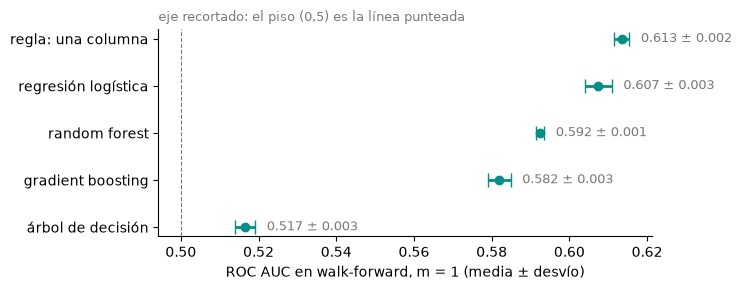

In [13]:
# La misma tabla, dibujada: el punto es la media y la barra, un desvío a cada lado
tabla = comparacion.drop(index="piso (dummy)").sort_values("AUC")
fig, ax = plt.subplots(figsize=(7.5, 3))
ax.errorbar(tabla["AUC"], tabla.index, xerr=tabla["desvío AUC"], fmt="o", color=VERDE_AZUL, ecolor=VERDE_AZUL,
            elinewidth=2, capsize=5)
for nombre, fila in tabla.iterrows():
    ax.text(fila["AUC"] + fila["desvío AUC"] + 0.003, nombre, f"{fila['AUC']:.3f} ± {fila['desvío AUC']:.3f}",
            va="center", fontsize=9, color=GRIS)
ax.axvline(0.5, color=GRIS, lw=0.8, ls="--")
ax.set_xlabel("ROC AUC en walk-forward, m = 1 (media ± desvío)")
ax.set_title("eje recortado: el piso (0,5) es la línea punteada", fontsize=9, color=GRIS, loc="left")
plt.tight_layout()
plt.show()

In [14]:
regla, logistica = comparacion.loc["regla: una columna"], comparacion.loc["regresión logística"]
mejor_comp = comparacion.drop(index=["piso (dummy)", "regla: una columna"])["AUC"].idxmax()
brechas = (comparacion["AUC en train"] - comparacion["AUC"]).drop(index="piso (dummy)")
leer(f'''**Lectura.** El piso da AUC {c(comparacion.loc['piso (dummy)', 'AUC'])} y accuracy {c(comparacion.loc['piso (dummy)', 'accuracy'])}. La regla de una sola columna llega a AUC **{c(regla['AUC'])}** (± {c(regla['desvío AUC'])}) y accuracy **{c(regla['accuracy'])}**: hay señal, y una sola columna la captura. La mejor de las cuatro familias con valores por defecto es `{mejor_comp}`, con AUC {c(comparacion.loc[mejor_comp, 'AUC'])} (± {c(comparacion.loc[mejor_comp, 'desvío AUC'])}), {'por encima' if comparacion.loc[mejor_comp, 'AUC'] > regla['AUC'] else 'por debajo'} de la regla por {c(abs(comparacion.loc[mejor_comp, 'AUC'] - regla['AUC']))}.

La columna de train muestra el sobreajuste: el árbol sin límite llega a {c(comparacion.loc['árbol de decisión', 'AUC en train'])} en train y {c(comparacion.loc['árbol de decisión', 'AUC'])} en validación (brecha {c(brechas['árbol de decisión'])}), y el bosque a {c(comparacion.loc['random forest', 'AUC en train'])}. Memorizan las partidas de entrenamiento. La logística con las 66 columnas también tiene brecha ({c(brechas['regresión logística'])}), de otra naturaleza: no memoriza partidas. Con 66 columnas para estimar a partir de 10§000 partidas puede ajustarse a rarezas de ese corte; una causa posible es que el meta se haya movido entre un corte y el siguiente (un parche, un héroe que se pone de moda), otra es el simple exceso de columnas, y con estas pruebas no se pueden separar. La regla de una columna no tiene brecha ({c(brechas['regla: una columna'])}): lo que acierta en train lo acierta en un corte que no vio.''')

**Lectura.** El piso da AUC 0,500 y accuracy 0,501. La regla de una sola columna llega a AUC **0,613** (± 0,002) y accuracy **0,580**: hay señal, y una sola columna la captura. La mejor de las cuatro familias con valores por defecto es `regresión logística`, con AUC 0,607 (± 0,003), por debajo de la regla por 0,006.

La columna de train muestra el sobreajuste: el árbol sin límite llega a 1,000 en train y 0,517 en validación (brecha 0,483), y el bosque a 1,000. Memorizan las partidas de entrenamiento. La logística con las 66 columnas también tiene brecha (0,019), de otra naturaleza: no memoriza partidas. Con 66 columnas para estimar a partir de 10.000 partidas puede ajustarse a rarezas de ese corte; una causa posible es que el meta se haya movido entre un corte y el siguiente (un parche, un héroe que se pone de moda), otra es el simple exceso de columnas, y con estas pruebas no se pueden separar. La regla de una columna no tiene brecha (-0,003): lo que acierta en train lo acierta en un corte que no vio.

### 4.3 Qué le pasaría al número si los pedazos se armaran al azar

La misma comparación, con una validación cruzada estratificada al azar (`StratifiedKFold`) sobre los cortes de entrenamiento juntos, en lugar del walk-forward. Si las partidas de un mismo corte fueran independientes del resto, los dos números tendrían que coincidir. La comparación no es pura: al azar cada turno entrena con el 80 % de todos los cortes, no con uno solo, así que la diferencia mezcla ver el mismo meta de los dos lados con entrenar con más partidas.


In [15]:
from sklearn.model_selection import StratifiedKFold

al_azar = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
validaciones = pd.DataFrame({nombre: {"walk-forward (m = 1)": comparacion.loc[nombre, "AUC"],
                                      "al azar (StratifiedKFold)": medir(modelos[nombre], cv=al_azar)["AUC"]}
                             for nombre in ["regla: una columna", "regresión logística", "gradient boosting"]}).T
validaciones["diferencia"] = validaciones["al azar (StratifiedKFold)"] - validaciones["walk-forward (m = 1)"]
validaciones.round(3)

,walk-forward (m = 1),al azar (StratifiedKFold),diferencia
regla: una columna,0.613,0.612,-0.002
regresión logística,0.607,0.617,0.010
gradient boosting,0.582,0.608,0.026


In [16]:
d = validaciones["diferencia"]
leer(f'''Al azar, la regla de una columna cambia {c(d['regla: una columna'])}, y la logística con las 66 columnas {c(d['regresión logística'])}; el boosting, {c(d['gradient boosting'])}. La regla casi no depende de cómo se parta: usa una columna que se recalcula en cada corte con las estadísticas de ese momento. Los modelos que aprenden un peso por héroe sí dependen de cómo se parta: {'con la partición al azar el número les sube' if d.drop('regla: una columna').max() > 0 else 'aun con la partición al azar el número no les sube'}. Puede deberse a que ven el meta de cada corte de los dos lados, o simplemente a que cada turno entrena con más partidas (ver la nota de arriba); con estos datos no se puede separar una causa de la otra. Sea cual sea, esa diferencia es la que el walk-forward no deja pasar.''')

Al azar, la regla de una columna cambia -0,002, y la logística con las 66 columnas 0,010; el boosting, 0,026. La regla casi no depende de cómo se parta: usa una columna que se recalcula en cada corte con las estadísticas de ese momento. Los modelos que aprenden un peso por héroe sí dependen de cómo se parta: con la partición al azar el número les sube. Puede deberse a que ven el meta de cada corte de los dos lados, o simplemente a que cada turno entrena con más partidas (ver la nota de arriba); con estos datos no se puede separar una causa de la otra. Sea cual sea, esa diferencia es la que el walk-forward no deja pasar.

## 5. El ajuste

Se ajustan las cuatro familias, no sólo la que va ganando: es la única forma de saber si el orden de la sección 4 es de las familias o de los valores por defecto. Cada grilla mueve los hiperparámetros que controlan la complejidad de su familia; la de la logística mueve además **qué bloques de columnas** usa. Todo con el mismo walk-forward, eligiendo por AUC.

In [17]:
from sklearn.model_selection import GridSearchCV

grillas = {
    "regresión logística": (armar(LogisticRegression(max_iter=5000)),
                            {"elegir__bloques": [UNA] + [(b,) for b in ORDEN] + [TODAS],
                             "modelo__C": [0.001, 0.01, 0.1, 1, 10]}),
    "árbol de decisión":   (armar(DecisionTreeClassifier(random_state=SEMILLA)),
                            {"modelo__max_depth": [3, 6, 10], "modelo__min_samples_leaf": [20, 100, 500]}),
    "random forest":       (armar(RandomForestClassifier(n_estimators=200, n_jobs=1, random_state=SEMILLA)),
                            {"modelo__max_depth": [6, 12, None], "modelo__min_samples_leaf": [20, 100]}),
    "gradient boosting":   (armar(HistGradientBoostingClassifier(random_state=SEMILLA)),
                            {"modelo__learning_rate": [0.03, 0.1], "modelo__max_leaf_nodes": [7, 31],
                             "modelo__max_iter": [100, 300]}),
}

busquedas = {nombre: GridSearchCV(p, g, cv=cv, scoring=ESCALA, refit="auc", n_jobs=-1, return_train_score=True)
                     .fit(X_train, y_train, groups=g_train)
             for nombre, (p, g) in grillas.items()}

pd.DataFrame({nombre: {"AUC por defecto (4.2)": comparacion.loc[nombre, "AUC"],
                       "AUC mejor de la grilla": b.best_score_,
                       "desvío": b.cv_results_["std_test_auc"][b.best_index_],
                       "accuracy de ese": b.cv_results_["mean_test_acc"][b.best_index_],
                       "combinaciones": len(b.cv_results_["params"])}
              for nombre, b in busquedas.items()}).T.round(3)

,AUC por defecto (4.2),AUC mejor de la grilla,desvío,accuracy de ese,combinaciones
regresión logística,0.607,0.616,0.002,0.582,30.0
árbol de decisión,0.517,0.606,0.000,0.579,9.0
random forest,0.592,0.611,0.003,0.580,6.0
gradient boosting,0.582,0.611,0.000,0.580,8.0


In [18]:
# Con qué hiperparámetros llegó cada familia a su mejor
def legible(v):
    return NOMBRE_BLOQUES.get(v, v) if isinstance(v, tuple) else v

pd.DataFrame({nombre: {k.split("__")[-1]: legible(v) for k, v in b.best_params_.items()}
              for nombre, b in busquedas.items()}).T.fillna("")

,bloques,C,max_depth,min_samples_leaf,learning_rate,max_iter,max_leaf_nodes
regresión logística,winrates (3),10,,,,,
árbol de decisión,,,3.0,500.0,,,
random forest,,,6.0,20.0,,,
gradient boosting,,,,,0.03,100.0,7.0


### 5.1 La tabla entera de la logística, no sólo el ganador

In [19]:
def tabla_de(busqueda):
    '''cv_results_ reducido a lo que se lee: hiperparámetros, AUC y accuracy en validación, AUC en train.'''
    r = pd.DataFrame(busqueda.cv_results_)
    params = [k for k in r.columns if k.startswith("param_")]
    t = r[params + ["mean_test_auc", "std_test_auc", "mean_test_acc", "mean_train_auc"]].copy()
    for p in params:
        t[p] = t[p].map(legible)
    return (t.rename(columns=lambda k: k.split("__")[-1].replace("param_", ""))
             .sort_values("mean_test_auc", ascending=False))

tabla_logistica = tabla_de(busquedas["regresión logística"])
tabla_logistica.round(4)

,bloques,C,mean_test_auc,std_test_auc,mean_test_acc,mean_train_auc
9,winrates (3),10.000,0.6155,0.0016,0.5820,0.6131
8,winrates (3),1.000,0.6155,0.0018,0.5817,0.6130
7,winrates (3),0.100,0.6147,0.0020,0.5818,0.6119
6,winrates (3),0.010,0.6140,0.0019,0.5816,0.6107
22,composición (38),0.100,0.6140,0.0024,0.5795,0.6212
24,composición (38),10.000,0.6140,0.0024,0.5799,0.6212
23,composición (38),1.000,0.6140,0.0024,0.5798,0.6212
5,winrates (3),0.001,0.6139,0.0019,0.5817,0.6104
21,composición (38),0.010,0.6139,0.0025,0.5796,0.6212
17,fuerza (4),0.100,0.6135,0.0021,0.5802,0.6105


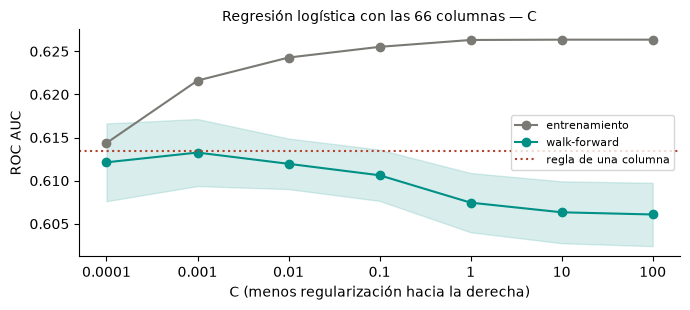

,0.0001,0.001,0.01,0.1,1,10,100
train,0.6144,0.6216,0.6243,0.6255,0.6263,0.6263,0.6264
validación,0.6121,0.6133,0.6120,0.6106,0.6074,0.6063,0.6061
desvío,0.0045,0.0039,0.0029,0.0030,0.0034,0.0036,0.0037


In [20]:
# La curva de validación de C para la logística con las 66 columnas: cuánto hay que frenarla
from sklearn.model_selection import validation_curve

valores_C = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]
tr, va = validation_curve(armar(LogisticRegression(max_iter=5000)), X_train, y_train, groups=g_train,
                          param_name="modelo__C", param_range=valores_C, cv=cv, scoring="roc_auc", n_jobs=-1)
etiquetas = [str(v) for v in valores_C]
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(etiquetas, tr.mean(axis=1), marker="o", color=GRIS, label="entrenamiento")
ax.plot(etiquetas, va.mean(axis=1), marker="o", color=VERDE_AZUL, label="walk-forward")
ax.fill_between(etiquetas, va.mean(axis=1) - va.std(axis=1), va.mean(axis=1) + va.std(axis=1), color=VERDE_AZUL, alpha=0.15)
ax.axhline(comparacion.loc["regla: una columna", "AUC"], color=TERRACOTA, ls=":", label="regla de una columna")
ax.set_xlabel("C (menos regularización hacia la derecha)"); ax.set_ylabel("ROC AUC"); ax.legend(fontsize=8)
ax.set_title("Regresión logística con las 66 columnas — C", fontsize=10)
plt.tight_layout()
plt.show()
pd.DataFrame({"train": tr.mean(axis=1), "validación": va.mean(axis=1), "desvío": va.std(axis=1)}, index=etiquetas).T.round(4)

### 5.2 La elección: el modelo de la composición

Se elige la **regresión logística sobre la composición**: las 38 columnas de héroes, con +1 si el héroe juega en A, −1 si juega en B y 0 si no está en la partida.

No es la combinación con más AUC de la tabla de arriba, pero sus valores son prácticamente los mismos que los de las mejores, y los consigue **sin ver las estadísticas de los héroes**: recibe sólo qué personajes eligió cada equipo y aprende, de los resultados de las partidas, cuánta ventaja le da cada uno a su equipo. Eso es, al fin y al cabo, el objetivo del proyecto: saber quién gana conociendo la composición de los equipos.

El criterio, en dos pasos:

1. **El empate.** Entran en la discusión las combinaciones que quedan a menos de un desvío de la mejor: una diferencia menor que el desvío no es una diferencia.
2. **Dentro del empate, la que no depende de una tabla externa.** Todos los bloques salvo la composición se calculan con las estadísticas de los 14 días anteriores al corte —winrates individuales, de cada cruce y de cada pareja—, que la aplicación tendría que bajar y mantener al día para poder predecir una partida. La composición se arma con los 12 héroes elegidos y nada más.

**Qué cambió respecto de la Entrega 3.** En la versión presentada, el desempate dentro del empate era «la que usa menos columnas» (abajo está qué elegía ese criterio). Contar columnas trata igual a una columna que se lee de la partida y a una que resume una tabla de winrates calculada afuera; el criterio nuevo cuenta lo que el modelo necesita para predecir. El cambio sale de la devolución de la Entrega 3, y se deja escrito para que se vea.

In [21]:
# El empate de la grilla de la sección 5, bloque por bloque, y qué necesita cada uno para predecir
lr = busquedas["regresión logística"]
r = pd.DataFrame(lr.cv_results_)
r["bloques"] = r["param_elegir__bloques"].map(legible)
r["n_columnas"] = r["param_elegir__bloques"].map(lambda b: len(columnas_de(b)))
mejor_lr = r.loc[lr.best_index_]
umbral = mejor_lr["mean_test_auc"] - mejor_lr["std_test_auc"]
r["en el empate"] = r["mean_test_auc"] >= umbral

COMPOSICION_B = ("composicion",)
por_bloque = (r.sort_values("mean_test_auc", ascending=False).groupby("bloques", sort=False).first()
              [["n_columnas", "param_modelo__C", "mean_test_auc", "std_test_auc", "mean_test_acc", "en el empate"]])
por_bloque.columns = ["columnas", "mejor C", "AUC", "desvío AUC", "accuracy", "¿en el empate?"]
por_bloque["¿necesita estadísticas de héroes?"] = np.where(por_bloque.index == legible(COMPOSICION_B), "no", "sí")

# el criterio de la Entrega 3 (menos columnas y, a igualdad, más regularización), para tenerlo de referencia
elegida_e3 = r[r["en el empate"]].sort_values(["n_columnas", "param_modelo__C"]).iloc[0]
por_bloque.round(4)

,columnas,mejor C,AUC,desvío AUC,accuracy,¿en el empate?,¿necesita estadísticas de héroes?
bloques,,,,,,,
winrates (3),3,10.000,0.6155,0.0016,0.5820,True,sí
composición (38),38,0.100,0.6140,0.0024,0.5795,True,no
fuerza (4),4,0.100,0.6135,0.0021,0.5802,False,sí
una columna,1,10.000,0.6135,0.0019,0.5799,False,sí
todas (66),66,0.001,0.6133,0.0039,0.5814,False,sí
counter_synergy (22),22,0.001,0.6030,0.0070,0.5751,False,sí


La regla de una columna de la sección 4.1 sigue siendo la vara, y la composición no le gana por más que el desvío: empatan. Lo que las distingue es **de dónde salen los pesos**. El DAG calcula `hero_winrate_adv_mean`, la columna de la regla, como el winrate promedio de los héroes de A menos el de los de B (`build_match_row`, en `include/deadlock/transform.py`). Con la composición en ±1, eso es lo mismo que

`hero_winrate_adv_mean = (1/6) · Σ wₕ · heroₕ`

donde `heroₕ` es la columna de composición del héroe *h* y `wₕ` su ventaja de winrate en los 14 días anteriores al corte. La celda de abajo lo comprueba corte por corte con las tablas que guardó el DAG (`stat_tables.pkl`).

In [22]:
# ¿La columna de la regla es la composición con pesos fijos? Se reconstruye con las tablas que guardó el DAG
import pickle


def winrates_del_corte(corte):
    '''La ventaja de winrate de cada héroe en los 14 días anteriores al corte, en el orden de schema.COMPOSICION.'''
    with open(PLATA / f"corte={corte}" / "stat_tables.pkl", "rb") as f:
        tablas = pickle.load(f)
    return pd.Series([tablas["hero"].get(h, 0.0) for h, _ in schema.HEROES], index=schema.COMPOSICION)


reconstruccion = {}
for corte, t in df.groupby("corte"):
    rehecha = t[schema.COMPOSICION].to_numpy() @ winrates_del_corte(corte).to_numpy() / 6
    reconstruccion[corte] = np.abs(rehecha - t["hero_winrate_adv_mean"].to_numpy()).max()
assert max(reconstruccion.values()) < 1e-9, "la columna de la regla no es una combinación lineal de la composición"
pd.Series(reconstruccion, name="máxima diferencia con hero_winrate_adv_mean")

2026-08-20    1.387779e-17
2026-08-27    1.387779e-17
2026-09-03    2.775558e-17
2026-09-10    1.387779e-17
2026-09-20    1.387779e-17
Name: máxima diferencia con hero_winrate_adv_mean, dtype: float64

In [23]:
comp_fila, mejor_fila = por_bloque.loc[legible(COMPOSICION_B)], por_bloque.iloc[0]
en_empate = por_bloque.index[por_bloque["¿en el empate?"]].tolist()
assert comp_fila["¿en el empate?"], "la composición quedó fuera del empate: el criterio de arriba no la elige"
leer(f'''La mejor combinación de la grilla es `{mejor_fila.name}`, con AUC {c(mejor_fila['AUC'], 4)} ± {c(mejor_fila['desvío AUC'], 4)}, así que el empate llega hasta {c(umbral, 4)}. La composición da **{c(comp_fila['AUC'], 4)}** ± {c(comp_fila['desvío AUC'], 4)}: {c(mejor_fila['AUC'] - comp_fila['AUC'], 4)} por debajo de la mejor, menos que el desvío. En el empate quedan {' y '.join(f'`{b}`' for b in en_empate) if len(en_empate) == 2 else ', '.join(f'`{b}`' for b in en_empate)}, y de ellos la composición es la única que no necesita las estadísticas de los héroes. Con el criterio de la Entrega 3 (menos columnas) el elegido era `{legible(elegida_e3['param_elegir__bloques'])}` con `C = {elegida_e3['param_modelo__C']:g}`; queda como referencia en el test de la sección 7.

La reconstrucción da una diferencia máxima de {max(reconstruccion.values()):.0e} en los {len(reconstruccion)} cortes: la columna de la regla **es** una combinación de las 38 columnas de composición, con los pesos fijados de antemano por las estadísticas de la API. Dicho de otra forma, la regla de una columna es una logística sobre la composición con los pesos *prestados*, y la logística sobre la composición es el mismo modelo con los pesos *aprendidos* de los resultados. Que den el mismo AUC quiere decir que las partidas de entrenamiento alcanzan para aprender solas lo que la API calcula con sus estadísticas. La sección 7§2 pone los dos juegos de pesos uno al lado del otro.''')

La mejor combinación de la grilla es `winrates (3)`, con AUC 0,6155 ± 0,0016, así que el empate llega hasta 0,6139. La composición da **0,6140** ± 0,0024: 0,0016 por debajo de la mejor, menos que el desvío. En el empate quedan `winrates (3)` y `composición (38)`, y de ellos la composición es la única que no necesita las estadísticas de los héroes. Con el criterio de la Entrega 3 (menos columnas) el elegido era `winrates (3)` con `C = 0.01`; queda como referencia en el test de la sección 7.

La reconstrucción da una diferencia máxima de 3e-17 en los 5 cortes: la columna de la regla **es** una combinación de las 38 columnas de composición, con los pesos fijados de antemano por las estadísticas de la API. Dicho de otra forma, la regla de una columna es una logística sobre la composición con los pesos *prestados*, y la logística sobre la composición es el mismo modelo con los pesos *aprendidos* de los resultados. Que den el mismo AUC quiere decir que las partidas de entrenamiento alcanzan para aprender solas lo que la API calcula con sus estadísticas. La sección 7.2 pone los dos juegos de pesos uno al lado del otro.

### 5.3 Las otras familias, sobre las mismas 38 columnas

La comparación de la sección 4 y las grillas de la sección 5 se hicieron sobre las 66 columnas. Elegida la composición, las familias se vuelven a comparar **sobre las mismas 38 columnas**, con el mismo walk-forward y las mismas grillas de la sección 5. Es también una pregunta de juego: un árbol, un bosque o un boosting pueden combinar héroes («si está X y enfrente está Y…»), cosa que una logística no puede. Si hubiera cruces o parejas que importan y se pudieran aprender de estas partidas, estas familias deberían ganarle.

La regla es la de la sección 5: una familia más compleja se elige sólo si le gana a la logística por más que el desvío de ésta.

In [24]:
busquedas_comp = {}
for nombre, (pipe, grilla) in grillas.items():
    if nombre == "regresión logística":
        grilla = {"modelo__C": grilla["modelo__C"]}            # las columnas ya están elegidas: sólo se mueve C
    busquedas_comp[nombre] = GridSearchCV(clone(pipe).set_params(elegir__bloques=COMPOSICION_B), grilla, cv=cv, scoring=ESCALA,
                                          refit="auc", n_jobs=-1, return_train_score=True).fit(X_train, y_train, groups=g_train)


def resumen_busqueda(b):
    i = b.best_index_
    return {"AUC": b.best_score_, "desvío AUC": b.cv_results_["std_test_auc"][i],
            "accuracy": b.cv_results_["mean_test_acc"][i], "AUC en train": b.cv_results_["mean_train_auc"][i]}


familias_comp = pd.concat([comparacion.loc[["piso (dummy)", "regla: una columna"], ["AUC", "desvío AUC", "accuracy", "AUC en train"]],
                           pd.DataFrame({n: resumen_busqueda(b) for n, b in busquedas_comp.items()}).T]).astype(float)
hiper_comp = pd.Series({n: ", ".join(f"{k.split('__')[-1]}={v}" for k, v in b.best_params_.items()) for n, b in busquedas_comp.items()})
familias_comp.round(4).assign(**{"mejores hiperparámetros": hiper_comp}).fillna({"mejores hiperparámetros": "referencia"})

,AUC,desvío AUC,accuracy,AUC en train,mejores hiperparámetros
piso (dummy),0.5000,0.0000,0.5012,0.5000,referencia
regla: una columna,0.6135,0.0019,0.5798,0.6101,referencia
regresión logística,0.6140,0.0024,0.5795,0.6212,C=0.1
árbol de decisión,0.5481,0.0044,0.5389,0.6107,"max_depth=10, min_samples_leaf=100"
random forest,0.5927,0.0028,0.5658,0.7921,"max_depth=None, min_samples_leaf=20"
gradient boosting,0.5921,0.0012,0.5668,0.6921,"learning_rate=0.1, max_iter=100, max_leaf_nodes=7"


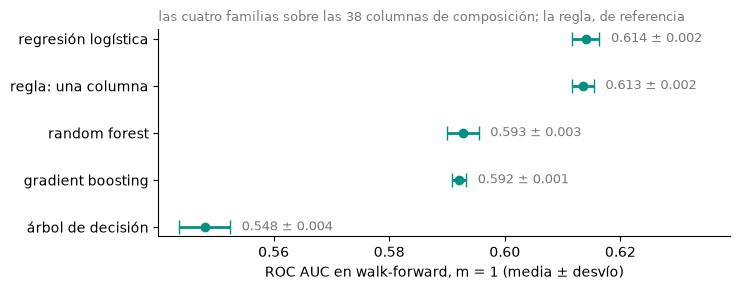

In [25]:
# La misma tabla, dibujada: el punto es la media y la barra, un desvío a cada lado
tabla = familias_comp.drop(index="piso (dummy)").sort_values("AUC")
fig, ax = plt.subplots(figsize=(7.5, 3))
ax.errorbar(tabla["AUC"], tabla.index, xerr=tabla["desvío AUC"], fmt="o", color=VERDE_AZUL, ecolor=VERDE_AZUL, elinewidth=2, capsize=5)
for nombre, fila in tabla.iterrows():
    ax.text(fila["AUC"] + fila["desvío AUC"] + 0.002, nombre, f"{fila['AUC']:.3f} ± {fila['desvío AUC']:.3f}", va="center", fontsize=9, color=GRIS)
ax.set_xlim(right=tabla["AUC"].max() + 0.025)
ax.set_xlabel("ROC AUC en walk-forward, m = 1 (media ± desvío)")
ax.set_title("las cuatro familias sobre las 38 columnas de composición; la regla, de referencia", fontsize=9, color=GRIS, loc="left")
plt.tight_layout()
plt.show()

In [26]:
lr_comp = busquedas_comp["regresión logística"]
sd_lr_comp = familias_comp.loc["regresión logística", "desvío AUC"]
otra_comp = max((n for n in busquedas_comp if n != "regresión logística"), key=lambda n: busquedas_comp[n].best_score_)
ventaja_otra_comp = busquedas_comp[otra_comp].best_score_ - lr_comp.best_score_
gana_complejo_comp = ventaja_otra_comp > sd_lr_comp
brecha_comp = familias_comp["AUC en train"] - familias_comp["AUC"]
leer(f'''Sobre la composición, la logística llega a AUC **{c(lr_comp.best_score_, 4)}** (± {c(sd_lr_comp, 4)}), y la mejor de las otras familias, `{otra_comp}`, a {c(busquedas_comp[otra_comp].best_score_, 4)}: {'le gana por más que el desvío, así que la familia compleja se justificaría' if gana_complejo_comp else f"queda {c(-ventaja_otra_comp, 4)} por debajo, así que se queda la logística"}. El árbol no pasa de {c(familias_comp.loc['árbol de decisión', 'AUC'], 4)}, y el bosque tiene una brecha con train de {c(brecha_comp['random forest'])}: las combinaciones de héroes que arman los árboles describen las partidas de un corte y no se repiten en el siguiente. Lo que la composición sabe decir, lo dice sumando un peso por héroe; la sección 6§2 hace la misma prueba con la logística, agregándole las parejas de héroes como columnas.''')

Sobre la composición, la logística llega a AUC **0,6140** (± 0,0024), y la mejor de las otras familias, `random forest`, a 0,5927: queda 0,0213 por debajo, así que se queda la logística. El árbol no pasa de 0,5481, y el bosque tiene una brecha con train de 0,199: las combinaciones de héroes que arman los árboles describen las partidas de un corte y no se repiten en el siguiente. Lo que la composición sabe decir, lo dice sumando un peso por héroe; la sección 6.2 hace la misma prueba con la logística, agregándole las parejas de héroes como columnas.

### 5.4 El ajuste de la logística sobre la composición

La grilla de la sección 5 movió sólo `C` para la composición, siempre escalando. Acá se ajusta el modelo elegido con tres hiperparámetros:

- **`C`**, cuánto se frena a los pesos.
- **La multa** (`l1_ratio`): 0 es l2, que achica todos los pesos; 1 es l1, que puede dejar héroes con peso cero.
- **Escalar o no.** Sin escalar, cada peso se lee directo: es cuánto suben los log-odds de que gane A cuando el héroe juega en A en lugar de no estar.

Además del AUC y la accuracy se informa el **log loss**, que mide si las probabilidades están bien dichas y no sólo bien ordenadas: es lo que la sección 2.2 dejó pendiente, y lo que va a mostrar la aplicación.

El criterio, declarado antes de correr: de las combinaciones a menos de un desvío de la mejor por AUC, se prefieren las que **no escalan y usan l2** —sus pesos se leen en log-odds y, como en cada partida hay seis +1 y seis −1, la multa l2 los deja sumando cero, así que cada peso se lee contra el héroe promedio—; entre ésas, la de **menor log loss**.

In [27]:
ESCALA_PROB = {**ESCALA, "logloss": "neg_log_loss"}
grilla_comp = [{"escalar": [StandardScaler(), "passthrough"], "modelo__C": [0.001, 0.01, 0.1, 1, 10],
                "modelo__l1_ratio": [0.0], "modelo__solver": ["lbfgs"]},
               {"escalar": [StandardScaler(), "passthrough"], "modelo__C": [0.001, 0.01, 0.1, 1, 10],
                "modelo__l1_ratio": [1.0], "modelo__solver": ["liblinear"]}]      # la l1 necesita otro solver
ajuste = GridSearchCV(armar(LogisticRegression(max_iter=5000), COMPOSICION_B), grilla_comp, cv=cv, scoring=ESCALA_PROB,
                      refit="auc", n_jobs=-1, return_train_score=True).fit(X_train, y_train, groups=g_train)

t = pd.DataFrame(ajuste.cv_results_)
tabla_ajuste = pd.DataFrame({
    "escalar": t["param_escalar"].map(lambda v: "no" if isinstance(v, str) else "sí"),
    "multa": t["param_modelo__l1_ratio"].map(lambda v: "l1" if v == 1 else "l2"),
    "C": t["param_modelo__C"].astype(float),
    "AUC": t["mean_test_auc"], "desvío AUC": t["std_test_auc"], "accuracy": t["mean_test_acc"],
    "log loss": -t["mean_test_logloss"], "AUC en train": t["mean_train_auc"]}).sort_values("AUC", ascending=False)
tabla_ajuste.round(4)

,escalar,multa,C,AUC,desvío AUC,accuracy,log loss,AUC en train
2,sí,l2,0.100,0.6140,0.0024,0.5795,0.6723,0.6212
4,sí,l2,10.000,0.6140,0.0024,0.5799,0.6724,0.6212
3,sí,l2,1.000,0.6140,0.0024,0.5798,0.6724,0.6212
14,sí,l1,10.000,0.6140,0.0024,0.5796,0.6724,0.6212
19,no,l1,10.000,0.6140,0.0024,0.5797,0.6724,0.6212
13,sí,l1,1.000,0.6139,0.0024,0.5795,0.6723,0.6212
18,no,l1,1.000,0.6139,0.0025,0.5794,0.6723,0.6212
9,no,l2,10.000,0.6139,0.0024,0.5798,0.6724,0.6212
8,no,l2,1.000,0.6139,0.0024,0.5798,0.6724,0.6212
7,no,l2,0.100,0.6139,0.0025,0.5800,0.6723,0.6212


In [28]:
mejor_aj = tabla_ajuste.iloc[0]
empate_aj = tabla_ajuste[tabla_ajuste["AUC"] >= mejor_aj["AUC"] - mejor_aj["desvío AUC"]]
preferidas = empate_aj[(empate_aj["escalar"] == "no") & (empate_aj["multa"] == "l2")]
elegida_aj = (preferidas if len(preferidas) else empate_aj).sort_values("log loss").iloc[0]

NOMBRE_FINAL = "regresión logística sobre la composición"
modelo_final = clone(ajuste.estimator).set_params(**ajuste.cv_results_["params"][elegida_aj.name])
auc_cv_final, desvio_cv_final = elegida_aj["AUC"], elegida_aj["desvío AUC"]
C_final = modelo_final.get_params()["modelo__C"]
pd.Series({"combinaciones en el empate": f"{len(empate_aj)} de {len(tabla_ajuste)}",
           "de ésas, sin escalar y con l2": len(preferidas),
           "elegida": f"escalar: {elegida_aj['escalar']} · multa {elegida_aj['multa']} · C = {elegida_aj['C']:g}",
           "AUC en validación": round(auc_cv_final, 4), "desvío": round(desvio_cv_final, 4),
           "log loss": round(elegida_aj["log loss"], 4), "AUC en train": round(elegida_aj["AUC en train"], 4)})

combinaciones en el empate                               15 de 20
de ésas, sin escalar y con l2                                   4
elegida                          escalar: no · multa l2 · C = 0.1
AUC en validación                                          0.6139
desvío                                                     0.0025
log loss                                                   0.6723
AUC en train                                               0.6212
dtype: object

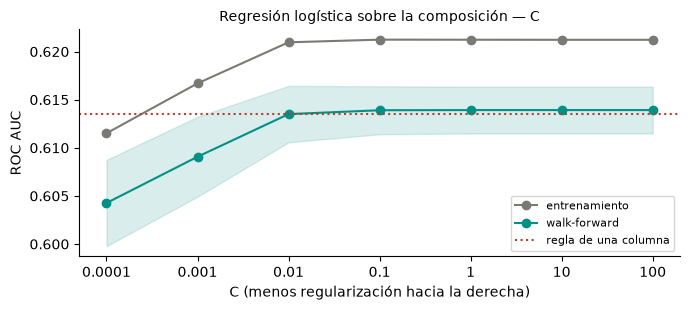

,0.0001,0.001,0.01,0.1,1,10,100
train,0.6115,0.6167,0.6210,0.6212,0.6212,0.6212,0.6212
validación,0.6043,0.6091,0.6135,0.6139,0.6139,0.6139,0.6139
desvío,0.0045,0.0042,0.0029,0.0025,0.0024,0.0024,0.0024


In [29]:
# La curva de validación de C para el modelo elegido: cuánto hay que frenarlo
tr_c, va_c = validation_curve(clone(modelo_final), X_train, y_train, groups=g_train, param_name="modelo__C",
                              param_range=valores_C, cv=cv, scoring="roc_auc", n_jobs=-1)
etiquetas_C = [str(v) for v in valores_C]
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(etiquetas_C, tr_c.mean(axis=1), marker="o", color=GRIS, label="entrenamiento")
ax.plot(etiquetas_C, va_c.mean(axis=1), marker="o", color=VERDE_AZUL, label="walk-forward")
ax.fill_between(etiquetas_C, va_c.mean(axis=1) - va_c.std(axis=1), va_c.mean(axis=1) + va_c.std(axis=1), color=VERDE_AZUL, alpha=0.15)
ax.axhline(comparacion.loc["regla: una columna", "AUC"], color=TERRACOTA, ls=":", label="regla de una columna")
ax.set_xlabel("C (menos regularización hacia la derecha)"); ax.set_ylabel("ROC AUC"); ax.legend(fontsize=8)
ax.set_title("Regresión logística sobre la composición — C", fontsize=10)
plt.tight_layout()
plt.show()
pd.DataFrame({"train": tr_c.mean(axis=1), "validación": va_c.mean(axis=1), "desvío": va_c.std(axis=1)}, index=etiquetas_C).T.round(4)

In [30]:
l2 = tabla_ajuste[(tabla_ajuste["multa"] == "l2") & (tabla_ajuste["C"] >= 0.01)]["AUC"]
l1_fuerte = tabla_ajuste[tabla_ajuste["multa"] == "l1"].sort_values(["C", "AUC"]).iloc[0]
apariciones = X_train.loc[g_train.eq(g_train.max()), schema.COMPOSICION].ne(0).sum().mean()
brecha_C = tr_c.mean(axis=1) - va_c.mean(axis=1)
leer(f'''**Lectura.** Con l2 y `C` desde 0.01, el AUC se mueve entre {c(l2.min(), 4)} y {c(l2.max(), 4)}: la composición casi no depende de cuánto se la frene, porque en un corte cada héroe aparece en unas {miles(int(round(apariciones, -1)))} partidas y su peso se estima sin mucha ayuda. Escalar o no da lo mismo: las 38 columnas ya están en la misma escala. La l1 con mucha multa (`C = {l1_fuerte['C']:g}`) deja a todos los héroes en cero y cae a {c(l1_fuerte['AUC'], 4)}, el piso. La elegida da AUC **{c(auc_cv_final, 4)}** ± {c(desvio_cv_final, 4)} y log loss {c(elegida_aj['log loss'], 4)}.

La brecha con train es de {c(elegida_aj['AUC en train'] - auc_cv_final, 4)}, y la regla no tiene ({c(brechas['regla: una columna'], 4)}: le va igual o mejor en validación que en train). La composición aprende 38 pesos de un corte, y algo de lo que aprende es propio de ese corte. Frenarla no la cierra: con `C = {valores_C[0]:g}` la brecha todavía es {c(brecha_C[0], 4)} y el AUC en validación baja a {c(va_c.mean(axis=1)[0], 4)}.''')

**Lectura.** Con l2 y `C` desde 0,01, el AUC se mueve entre 0,6135 y 0,6140: la composición casi no depende de cuánto se la frene, porque en un corte cada héroe aparece en unas 3.160 partidas y su peso se estima sin mucha ayuda. Escalar o no da lo mismo: las 38 columnas ya están en la misma escala. La l1 con mucha multa (`C = 0.001`) deja a todos los héroes en cero y cae a 0,5000, el piso. La elegida da AUC **0,6139** ± 0,0025 y log loss 0,6723.

La brecha con train es de 0,0073, y la regla no tiene (-0,0034: le va igual o mejor en validación que en train). La composición aprende 38 pesos de un corte, y algo de lo que aprende es propio de ese corte. Frenarla no la cierra: con `C = 0.0001` la brecha todavía es 0,0072 y el AUC en validación baja a 0,6043.

### 5.5 La ventana: ¿más cortes, mejores pesos?

La sección 2.3 fijó `m = 1` por diseño y dejó escrito que no se comparó. Para la composición la pregunta pesa más que para la regla: la regla recibe los pesos ya calculados con 14 días de estadísticas, mientras que la composición tiene que aprenderlos de las partidas, y con más cortes tiene más partidas, pero de un meta más viejo.

Una ventana de `m` cortes deja menos pasos de validación cuanto más larga es, así que las ventanas se comparan **sobre los mismos cortes de validación**. El criterio, declarado antes: `m = 1` se mantiene salvo que una ventana más larga le gane, sobre los mismos cortes, por más que el desvío de `m = 1`.

In [31]:
def auc_por_corte(pipe, m):
    '''AUC del walk-forward con ventana de m cortes, indexado por el corte que se valida.'''
    v = VentanaDeslizante(m)
    validados = [g_train.iloc[val].iloc[0] for _, val in v.split(X_train, y_train, g_train)]
    res = cross_validate(pipe, X_train, y_train, groups=g_train, cv=v, scoring="roc_auc", n_jobs=-1)
    return pd.Series(res["test_score"], index=validados)


ventanas = pd.DataFrame({f"m = {m}": auc_por_corte(clone(modelo_final), m) for m in (1, 2, 3)}).T
comparacion_m = pd.DataFrame([{"ventana": f, "cortes validados": ", ".join(ventanas.loc[f].dropna().index),
                               "AUC con m = 1": ventanas.loc["m = 1", ventanas.loc[f].dropna().index].mean(),
                               "AUC con esta ventana": ventanas.loc[f].dropna().mean()}
                              for f in ventanas.index[1:]]).set_index("ventana")
comparacion_m["diferencia"] = comparacion_m["AUC con esta ventana"] - comparacion_m["AUC con m = 1"]
gana_ventana = comparacion_m[comparacion_m["diferencia"] > desvio_cv_final]
VENTANA_FINAL = int(gana_ventana.index[-1].split("= ")[1]) if len(gana_ventana) else VENTANA
display(Markdown("**AUC de cada ventana, por corte de validación**"), ventanas.round(4))
display(Markdown("**Cada ventana contra `m = 1`, sobre los mismos cortes**"), comparacion_m.round(4))

**AUC de cada ventana, por corte de validación**

,2026-08-27,2026-09-03,2026-09-10
m = 1,0.6114,0.6130,0.6173
m = 2,NaN,0.6162,0.6178
m = 3,NaN,NaN,0.6181


**Cada ventana contra `m = 1`, sobre los mismos cortes**

,cortes validados,AUC con m = 1,AUC con esta ventana,diferencia
ventana,,,,
m = 2,"2026-09-03, 2026-09-10",0.6152,0.6170,0.0018
m = 3,2026-09-10,0.6173,0.6181,0.0008


In [32]:
leer(f'''Con más cortes el AUC sube algo: {', '.join(f"{c(d, 4)} con `{v}`" for v, d in comparacion_m['diferencia'].items())}, sobre los mismos cortes de validación. Es lo esperable si los pesos se estiman mejor con más partidas, pero {'es menos que el desvío de `m = 1` (' + c(desvio_cv_final, 4) + '), y con uno o dos pasos de validación no alcanza para afirmarlo. Se queda `m = 1`, como en la sección 2§3; es lo primero que conviene volver a medir cuando el DAG sume cortes.' if VENTANA_FINAL == VENTANA else 'supera el desvío de `m = 1` (' + c(desvio_cv_final, 4) + '): el modelo final se entrena con `m = ' + str(VENTANA_FINAL) + '`.'}''')

Con más cortes el AUC sube algo: 0,0018 con `m = 2`, 0,0008 con `m = 3`, sobre los mismos cortes de validación. Es lo esperable si los pesos se estiman mejor con más partidas, pero es menos que el desvío de `m = 1` (0,0025), y con uno o dos pasos de validación no alcanza para afirmarlo. Se queda `m = 1`, como en la sección 2.3; es lo primero que conviene volver a medir cuando el DAG sume cortes.

### 5.6 Qué le pasaría al número de la composición si se partiera al azar

La sección 4.3 hizo esta pregunta para la regla, la logística con las 66 columnas y el boosting. La composición es el modelo que más depende de la partición en principio, porque aprende un peso por héroe a partir de las partidas, así que se mide igual: `StratifiedKFold` al azar sobre los cortes de entrenamiento juntos, con la misma advertencia (al azar cada turno entrena con más partidas).

In [33]:
azar_comp = medir(modelo_final, cv=al_azar)
tabla_azar = validaciones.copy()
tabla_azar.loc["composición (elegido)"] = [auc_cv_final, azar_comp["AUC"], azar_comp["AUC"] - auc_cv_final]
dv = validaciones["diferencia"]
leer(f'''Al azar, la composición cambia {c(azar_comp['AUC'] - auc_cv_final)}: {'mucho ' if azar_comp['AUC'] - auc_cv_final < dv['regresión logística'] / 2 else ''}menos que la logística con las 66 columnas ({c(dv['regresión logística'])}) y que el boosting ({c(dv['gradient boosting'])}). Sus pesos son de héroes, no de partidas, y pasan de un corte al siguiente casi enteros.''')
tabla_azar.round(3)

Al azar, la composición cambia 0,002: mucho menos que la logística con las 66 columnas (0,010) y que el boosting (0,026). Sus pesos son de héroes, no de partidas, y pasan de un corte al siguiente casi enteros.

,walk-forward (m = 1),al azar (StratifiedKFold),diferencia
regla: una columna,0.613,0.612,-0.002
regresión logística,0.607,0.617,0.010
gradient boosting,0.582,0.608,0.026
composición (elegido),0.614,0.616,0.002


### 5.7 El desbalance: una decisión con su número

No hay desbalance que corregir: A gana alrededor del 50 % de las veces en entrenamiento y en test, y no puede ser de otra forma porque A es una etiqueta arbitraria. La decisión es **no hacer nada**: ni `class_weight`, ni mover el umbral, que queda en 0,5 porque el problema es simétrico. Para que sea una decisión medida y no una omisión, el mismo modelo con `class_weight="balanced"`:

In [34]:
balanceado = medir(clone(modelo_final).set_params(modelo__class_weight="balanced"))
pd.Series({"proporción en que gana A (train)": y_train.mean(), "proporción en que gana A (test)": y_test.mean(),
           "AUC sin balancear": auc_cv_final, "AUC con class_weight='balanced'": balanceado["AUC"],
           "accuracy sin balancear": elegida_aj["accuracy"], "accuracy con class_weight='balanced'": balanceado["accuracy"]}).round(4)

proporción en que gana A (train)        0.5068
proporción en que gana A (test)         0.5021
AUC sin balancear                       0.6139
AUC con class_weight='balanced'         0.6139
accuracy sin balancear                  0.5800
accuracy con class_weight='balanced'    0.5806
dtype: float64

## 6. Lo que se probó sobre la composición y no aportó nada medible

Partiendo del modelo elegido, tres preguntas, cada una con el número con y sin:

- **6.1 ¿Le suma algo a la composición ver las estadísticas de los héroes?** Se le agrega cada bloque de ventajas de la sección 3, y `average_badge_diff`. Y al revés: qué se pierde al sacarle a las 66 columnas cada bloque, la composición incluida.
- **6.2 ¿Aprende qué héroe tiene ventaja sobre cuál?** La logística sobre la composición da un peso por héroe, no por pareja. Se le agregan como columnas propias los cruces (un héroe en A y otro en B) y las parejas de un mismo equipo, para que los aprenda de los datos.
- **6.3 ¿Hace falta un peso por héroe y por lado?** En lugar de una columna ±1, dos columnas por héroe: una si juega en A y otra si juega en B.

Cada prueba usa la logística con el `C` elegido en la sección 5.4 y el mismo walk-forward. Un cambio menor que el desvío de la composición sola no es un cambio.

### 6.1 Las estadísticas de los héroes, encima de la composición

Para poder sumarle columnas en otras escalas (las ventajas de souls están en miles), esta tabla escala todo con `StandardScaler`, y la composición sola se mide igual para que la comparación sea pareja.

In [35]:
def logistica_final():
    return LogisticRegression(max_iter=5000, C=C_final)


base_escalada = medir(armar(logistica_final(), COMPOSICION_B))
filas = [{"se suma": "nada (composición sola)", "columnas": 38, "AUC": base_escalada["AUC"], "desvío AUC": base_escalada["desvío AUC"]}]
for b in ("winrates", "counter_synergy", "fuerza", "rango", "todas"):
    bloques = TODAS if b == "todas" else COMPOSICION_B + (b,)
    m_ = medir(armar(logistica_final(), bloques))
    filas.append({"se suma": b, "columnas": len(columnas_de(bloques)), "AUC": m_["AUC"], "desvío AUC": m_["desvío AUC"]})
sumar_a_comp = pd.DataFrame(filas).set_index("se suma")
sumar_a_comp["Δ AUC vs. composición sola"] = sumar_a_comp["AUC"] - base_escalada["AUC"]
sumar_a_comp.round(4)

,columnas,AUC,desvío AUC,Δ AUC vs. composición sola
se suma,,,,
nada (composición sola),38,0.6140,0.0024,0.0000
winrates,41,0.6132,0.0032,-0.0008
counter_synergy,60,0.6114,0.0025,-0.0025
fuerza,42,0.6133,0.0029,-0.0006
rango,39,0.6142,0.0023,0.0003
todas,66,0.6106,0.0030,-0.0033


In [36]:
# Al revés: las 66 columnas sin cada bloque (con el C con que mejor le fue a las 66 en la grilla de la sección 5)
C_ref = r[r["param_elegir__bloques"] == TODAS].sort_values("mean_test_auc").iloc[-1]["param_modelo__C"]
for b in UNA + ORDEN:
    BLOQUES[f"todas_menos_{b}"] = [k for k in BLOQUES["todas"] if k not in BLOQUES[b]]
con_todas = medir(armar(LogisticRegression(max_iter=5000, C=C_ref), TODAS))
menos_uno = pd.DataFrame({b: {"columnas": len(BLOQUES[f"todas_menos_{b}"]),
                              "AUC": medir(armar(LogisticRegression(max_iter=5000, C=C_ref), (f"todas_menos_{b}",)))["AUC"]}
                          for b in UNA + ORDEN}).T
menos_uno["Δ AUC vs. las 66"] = menos_uno["AUC"] - con_todas["AUC"]
menos_uno.index = [f"las 66 sin {b}" for b in menos_uno.index]
menos_uno.round(4)

,columnas,AUC,Δ AUC vs. las 66
las 66 sin una_columna,65.0,0.6132,-0.0001
las 66 sin winrates,63.0,0.6118,-0.0015
las 66 sin counter_synergy,44.0,0.6139,0.0007
las 66 sin fuerza,62.0,0.6133,0.0000
las 66 sin composicion,28.0,0.6110,-0.0023


In [37]:
d_sumar = sumar_a_comp["Δ AUC vs. composición sola"].drop(index="nada (composición sola)")
sd_base = base_escalada["desvío AUC"]
restan = d_sumar[d_sumar < -sd_base]
mas_duele = menos_uno["Δ AUC vs. las 66"].idxmin()
y_lista = lambda xs: " y ".join([", ".join(xs[:-1]), xs[-1]] if len(xs) > 1 else xs)
ventajas_d = d_sumar.drop(index="rango")
suma_txt = ("Ningún bloque de ventajas le suma: todos dejan el AUC igual o más bajo" if ventajas_d.max() <= 0
            else f"Ningún bloque de ventajas le suma más que {c(ventajas_d.max(), 4)}")
resta_txt = (f", y {y_lista([f'`{b}`' for b in restan.index])} {'restan' if len(restan) > 1 else 'resta'} más que el desvío" if len(restan) else "")
leer(f'''**Sumar.** Con la composición sola el AUC es {c(base_escalada['AUC'], 4)} ± {c(sd_base, 4)}. {suma_txt}{resta_txt}: lo que las estadísticas dicen de cada héroe, la composición ya lo aprendió de las partidas. `average_badge_diff` (bloque `rango`) mueve el AUC {c(d_sumar['rango'], 4)} y sigue afuera, como se decidió en H4.

**Sacar.** Sobre las 66 columnas (AUC {c(con_todas['AUC'], 4)} ± {c(con_todas['desvío AUC'], 4)}), lo que más baja el AUC es sacar `{mas_duele.replace('las 66 sin ', '')}` ({c(menos_uno.loc[mas_duele, 'Δ AUC vs. las 66'], 4)}){', aunque dentro del desvío' if menos_uno.loc[mas_duele, 'Δ AUC vs. las 66'] > -con_todas['desvío AUC'] else ''}{': de todos los bloques, la composición es el que menos repite lo que dicen los otros' if mas_duele == 'las 66 sin composicion' else ''}.''')

**Sumar.** Con la composición sola el AUC es 0,6140 ± 0,0024. Ningún bloque de ventajas le suma: todos dejan el AUC igual o más bajo, y `counter_synergy` y `todas` restan más que el desvío: lo que las estadísticas dicen de cada héroe, la composición ya lo aprendió de las partidas. `average_badge_diff` (bloque `rango`) mueve el AUC 0,0003 y sigue afuera, como se decidió en H4.

**Sacar.** Sobre las 66 columnas (AUC 0,6133 ± 0,0039), lo que más baja el AUC es sacar `composicion` (-0,0023), aunque dentro del desvío: de todos los bloques, la composición es el que menos repite lo que dicen los otros.

### 6.2 Los cruces y las parejas, aprendidos de los datos

La logística elegida suma un peso por héroe: sabe cuánto inclina la balanza cada uno, pero no que un héroe en particular le gane a otro en particular. Para que pueda aprenderlo, `ParesDeHeroes` agrega a las 38 columnas una por cada pareja de héroes distintos (703):

- **cruces**: +1 si el primero juega en A y el segundo en B, −1 si es al revés, 0 si no se enfrentan;
- **parejas**: +1 si los dos juegan juntos en A, −1 si juntos en B, 0 si no.

Es un paso del pipeline como los demás, y se mide con la misma grilla de `C` para las tres variantes.

In [38]:
class ParesDeHeroes(BaseEstimator, TransformerMixin):
    '''Agrega a la composición una columna por pareja de héroes: los cruces (uno en A y otro en B) y/o las parejas de un mismo equipo.'''

    def __init__(self, cruces=True, parejas=False):
        self.cruces = cruces
        self.parejas = parejas

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        comp = np.asarray(X, dtype=float)
        en_a, en_b = (comp == 1).astype(float), (comp == -1).astype(float)
        i, j = np.triu_indices(comp.shape[1], 1)                   # las parejas de héroes distintos
        partes = [comp]
        if self.cruces:      # +1 si i juega en A y j en B, −1 si es al revés
            partes.append(en_a[:, i] * en_b[:, j] - en_b[:, i] * en_a[:, j])
        if self.parejas:     # +1 si i y j juegan juntos en A, −1 si juntos en B
            partes.append(en_a[:, i] * en_a[:, j] - en_b[:, i] * en_b[:, j])
        return np.hstack(partes)


VARIANTES = {(True, False): "cruces A×B", (False, True): "parejas del mismo equipo", (True, True): "cruces y parejas"}
C_PARES = [0.0001, 0.001, 0.01, 0.1]
pares = GridSearchCV(Pipeline([("elegir", ElegirColumnas(COMPOSICION_B)), ("pares", ParesDeHeroes()),
                               ("modelo", LogisticRegression(max_iter=5000))]),
                     [{"pares__cruces": [cr], "pares__parejas": [pa], "modelo__C": C_PARES} for cr, pa in VARIANTES],
                     cv=cv, scoring=ESCALA, refit="auc", n_jobs=-1, return_train_score=True).fit(X_train, y_train, groups=g_train)

tp = pd.DataFrame(pares.cv_results_)
muestra = X_train[schema.COMPOSICION].iloc[:2]
tabla_pares = pd.DataFrame({
    "variante": [VARIANTES[(p["pares__cruces"], p["pares__parejas"])] for p in tp["params"]],
    "columnas": [ParesDeHeroes(p["pares__cruces"], p["pares__parejas"]).transform(muestra).shape[1] for p in tp["params"]],
    "C": tp["param_modelo__C"].astype(float), "AUC": tp["mean_test_auc"], "desvío AUC": tp["std_test_auc"],
    "AUC en train": tp["mean_train_auc"]})
tabla_pares["Δ AUC vs. composición sola"] = tabla_pares["AUC"] - auc_cv_final
tabla_pares.round(4)

,variante,columnas,C,AUC,desvío AUC,AUC en train,Δ AUC vs. composición sola
0,cruces A×B,741,0.0001,0.6048,0.0045,0.6227,-0.0091
1,cruces A×B,741,0.0010,0.6092,0.0042,0.6397,-0.0047
2,cruces A×B,741,0.0100,0.5985,0.0042,0.6751,-0.0154
3,cruces A×B,741,0.1000,0.5800,0.0049,0.6903,-0.0339
4,parejas del mismo equipo,741,0.0001,0.6053,0.0043,0.6227,-0.0086
5,parejas del mismo equipo,741,0.0010,0.6103,0.0033,0.6381,-0.0036
6,parejas del mismo equipo,741,0.0100,0.6028,0.0010,0.6723,-0.0111
7,parejas del mismo equipo,741,0.1000,0.5840,0.0015,0.6906,-0.0299
8,cruces y parejas,1444,0.0001,0.6059,0.0044,0.6282,-0.0080
9,cruces y parejas,1444,0.0010,0.6101,0.0034,0.6546,-0.0038


In [39]:
mejor_pares = tabla_pares.sort_values("AUC", ascending=False).groupby("variante", sort=False).first()
ultimo_corte = X_train.loc[g_train.eq(g_train.max()), schema.COMPOSICION]
partidas_por_cruce = (ParesDeHeroes(True, False).transform(ultimo_corte)[:, len(schema.COMPOSICION):] != 0).sum(axis=0).mean()
peor_brecha = (tabla_pares["AUC en train"] - tabla_pares["AUC"]).max()
leer(f'''La mejor variante es `{mejor_pares['AUC'].idxmax()}`, con AUC {c(mejor_pares['AUC'].max(), 4)}: {c(mejor_pares['AUC'].max() - auc_cv_final, 4)} contra la composición sola ({c(auc_cv_final, 4)} ± {c(desvio_cv_final, 4)}). {'Ninguna de las tres le suma: todas quedan por debajo.' if (mejor_pares['AUC'] < auc_cv_final).all() else ''} Cuanto menos se las frena, más ganan en train y más pierden en validación (la brecha llega a {c(peor_brecha, 3)}): cada cruce aparece en unas {miles(int(round(partidas_por_cruce, -1)))} partidas por corte, y con 703 parejas el efecto de cada una, si existe, queda tapado por el ruido.

**El modelo elegido no sabe qué héroe le gana a cuál: sabe cuánto suma cada uno.** Aprender los cruces de las partidas pediría muchas más partidas por corte. La otra forma es traerlos calculados de afuera, que es lo que hacen las columnas `counter_` y `synergy_`, y la sección 6§1 mostró que tampoco le suman a la composición.''')

La mejor variante es `parejas del mismo equipo`, con AUC 0,6103: -0,0036 contra la composición sola (0,6139 ± 0,0025). Ninguna de las tres le suma: todas quedan por debajo. Cuanto menos se las frena, más ganan en train y más pierden en validación (la brecha llega a 0,171): cada cruce aparece en unas 510 partidas por corte, y con 703 parejas el efecto de cada una, si existe, queda tapado por el ruido.

**El modelo elegido no sabe qué héroe le gana a cuál: sabe cuánto suma cada uno.** Aprender los cruces de las partidas pediría muchas más partidas por corte. La otra forma es traerlos calculados de afuera, que es lo que hacen las columnas `counter_` y `synergy_`, y la sección 6.1 mostró que tampoco le suman a la composición.

### 6.3 Un peso por héroe y por lado

La codificación ±1 supone que un héroe vale lo mismo en A que en B, con el signo cambiado. `PorLado` lo deja libre: dos columnas por héroe (76), una que vale 1 si juega en A y otra que vale 1 si juega en B.

In [40]:
class PorLado(BaseEstimator, TransformerMixin):
    '''Dos columnas por héroe en lugar de una ±1: 1 si juega en A, y 1 si juega en B.'''

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        comp = np.asarray(X, dtype=float)
        return np.hstack([comp == 1, comp == -1]).astype(float)


por_lado = medir(Pipeline([("elegir", ElegirColumnas(COMPOSICION_B)), ("lado", PorLado()), ("modelo", logistica_final())]))
d_lado = por_lado["AUC"] - auc_cv_final
leer(f'''Con un peso por héroe y por lado el AUC es {c(por_lado['AUC'], 4)} ± {c(por_lado['desvío AUC'], 4)}, {c(d_lado, 4)} contra la composición ±1{', más que el desvío' if d_lado < -desvio_cv_final else ''}. Separar el lado duplica los pesos a estimar con las mismas partidas, y no aparece un efecto de lado que lo compense: la codificación ±1 es la que corresponde, y un héroe vale lo mismo en los dos equipos.''')

Con un peso por héroe y por lado el AUC es 0,6093 ± 0,0026, -0,0046 contra la composición ±1, más que el desvío. Separar el lado duplica los pesos a estimar con las mismas partidas, y no aparece un efecto de lado que lo compense: la codificación ±1 es la que corresponde, y un héroe vale lo mismo en los dos equipos.

### Resumen: lo que se probó sobre la composición

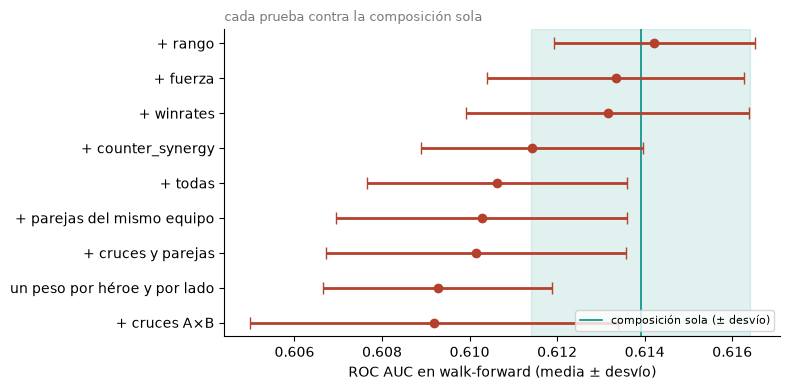

De las 9 pruebas, ninguna le suma a la composición más que el desvío (0,0025), y 6 restan más que el desvío. La composición sola, con un peso por héroe, es el modelo más chico que dice todo lo que estas columnas pueden decir.

,columnas,AUC,desvío AUC,Δ AUC vs. composición sola
+ winrates,41.0,0.6132,0.0032,-0.0008
+ counter_synergy,60.0,0.6114,0.0025,-0.0025
+ fuerza,42.0,0.6133,0.0029,-0.0006
+ rango,39.0,0.6142,0.0023,0.0003
+ todas,66.0,0.6106,0.0030,-0.0033
+ parejas del mismo equipo,741.0,0.6103,0.0033,-0.0036
+ cruces y parejas,1444.0,0.6101,0.0034,-0.0038
+ cruces A×B,741.0,0.6092,0.0042,-0.0047
un peso por héroe y por lado,76.0,0.6093,0.0026,-0.0046


In [41]:
pruebas = pd.concat([
    sumar_a_comp.drop(index="nada (composición sola)").rename(index=lambda b: f"+ {b}")[["columnas", "AUC", "desvío AUC", "Δ AUC vs. composición sola"]],
    mejor_pares[["columnas", "AUC", "desvío AUC", "Δ AUC vs. composición sola"]].rename(index=lambda v: f"+ {v}"),
    pd.DataFrame({"columnas": 76, "AUC": por_lado["AUC"], "desvío AUC": por_lado["desvío AUC"], "Δ AUC vs. composición sola": d_lado},
                 index=["un peso por héroe y por lado"])]).astype(float)

fig, ax = plt.subplots(figsize=(8, 4))
orden_pr = pruebas.sort_values("AUC")
ax.axvspan(auc_cv_final - desvio_cv_final, auc_cv_final + desvio_cv_final, color=VERDE_AZUL, alpha=0.12)
ax.axvline(auc_cv_final, color=VERDE_AZUL, lw=1.2, label="composición sola (± desvío)")
ax.errorbar(orden_pr["AUC"], orden_pr.index, xerr=orden_pr["desvío AUC"], fmt="o", color=TERRACOTA, ecolor=TERRACOTA, elinewidth=2, capsize=4)
ax.set_xlabel("ROC AUC en walk-forward (media ± desvío)"); ax.legend(fontsize=8, loc="lower right")
ax.set_title("cada prueba contra la composición sola", fontsize=9, color=GRIS, loc="left")
plt.tight_layout()
plt.show()
suman = pruebas.index[pruebas["Δ AUC vs. composición sola"] > desvio_cv_final]
leer(f'''De las {len(pruebas)} pruebas, {'ninguna le suma a la composición más que el desvío' if len(suman) == 0 else 'le suman más que el desvío ' + ', '.join(f'`{p}`' for p in suman)} ({c(desvio_cv_final, 4)}), y {(pruebas['Δ AUC vs. composición sola'] < -desvio_cv_final).sum()} restan más que el desvío. {'La composición sola, con un peso por héroe, es el modelo más chico que dice todo lo que estas columnas pueden decir.' if len(suman) == 0 else ''}''')
pruebas.round(4)

### 6.4 Por qué las ventajas no le suman: cuántas direcciones tienen las 28

La sección 6.1 mostró que sumarle las ventajas a la composición no cambia el AUC. Comprimirlas ayuda a ver por qué. Las 28 ventajas (fuerza individual, counters y sinergias) son variaciones de la misma idea —cuánto más fuertes son los héroes de A que los de B— y en la Entrega 2 (H3) correlacionaban fuerte entre sí. PCA (Práctica 3) las gira en direcciones ordenadas por la varianza que explican: si con pocas componentes un modelo rinde lo mismo que con las 28, la información de las ventajas está en pocas direcciones.

PCA es un transformador, así que entra al pipeline como un paso más, entre escalar y clasificar: en cada paso del walk-forward aprende las direcciones **sólo con el corte de entrenamiento**. El número de componentes es un hiperparámetro y se mide como cualquier otro, con el mismo walk-forward. Van tres familias: la logística, con el `C` con el que mejor le fue a las 66 columnas en la grilla de la sección 5 (el de la sección 6.1), y el árbol y el boosting con los hiperparámetros que ganaron en esa grilla (ajustados con las 66 columnas). La línea punteada de cada color es el mismo modelo con las 28 columnas originales, sin PCA; la gris, la regla de una columna.

In [42]:
# PCA como un paso más del pipeline: elegir las 28 ventajas, escalar, girar y quedarse con n componentes, clasificar
from sklearn.decomposition import PCA


def armar_pca(modelo, n):
    '''La receta de armar() con las 28 ventajas y un PCA de n componentes entre escalar y clasificar.'''
    return Pipeline([("elegir", ElegirColumnas(VENTAJAS)), ("escalar", StandardScaler()),
                     ("pca", PCA(n_components=n, random_state=SEMILLA)), ("modelo", modelo)])


familias_pca = {"regresión logística": LogisticRegression(max_iter=5000, C=C_ref),
                "árbol de decisión":   busquedas["árbol de decisión"].best_estimator_.named_steps["modelo"],
                "gradient boosting":   busquedas["gradient boosting"].best_estimator_.named_steps["modelo"]}
columnas_ventajas = ElegirColumnas(VENTAJAS).fit(X_train).columnas_
COMPONENTES = [1, 2, 3, 5, 10, 20, len(columnas_ventajas)]

curva_pca = pd.DataFrame({nombre: {n: medir(armar_pca(clone(m), n))["AUC"] for n in COMPONENTES}
                          for nombre, m in familias_pca.items()})
sin_pca = pd.DataFrame({nombre: medir(armar(clone(m), VENTAJAS)) for nombre, m in familias_pca.items()}).T

# sólo para describir las direcciones (no para elegir nada): PCA ajustado con todas las partidas de entrenamiento
descripcion = Pipeline([("escalar", StandardScaler()), ("pca", PCA(random_state=SEMILLA))]).fit(X_train[columnas_ventajas])
varianza = descripcion.named_steps["pca"].explained_variance_ratio_.cumsum()
pc1 = descripcion.transform(X_train[columnas_ventajas])[:, 0]
corr_pc1 = abs(np.corrcoef(pc1, X_train["hero_winrate_adv_mean"])[0, 1])   # el signo de una componente es arbitrario

tabla_pca = curva_pca.copy()
tabla_pca.loc["sin PCA (las 28)"] = sin_pca["AUC"].astype(float)
tabla_pca.insert(0, "varianza explicada", [varianza[n - 1] for n in COMPONENTES] + [1.0])
tabla_pca.round(4)

,varianza explicada,regresión logística,árbol de decisión,gradient boosting
1,0.2606,0.6082,0.6042,0.6049
2,0.3831,0.6093,0.6006,0.6043
3,0.4802,0.6091,0.6005,0.6041
5,0.6402,0.6092,0.6003,0.6044
10,0.8888,0.6085,0.5995,0.6038
20,0.9871,0.6110,0.5972,0.6073
28,1.0000,0.6110,0.5971,0.6077
sin PCA (las 28),1.0000,0.6110,0.6056,0.6090


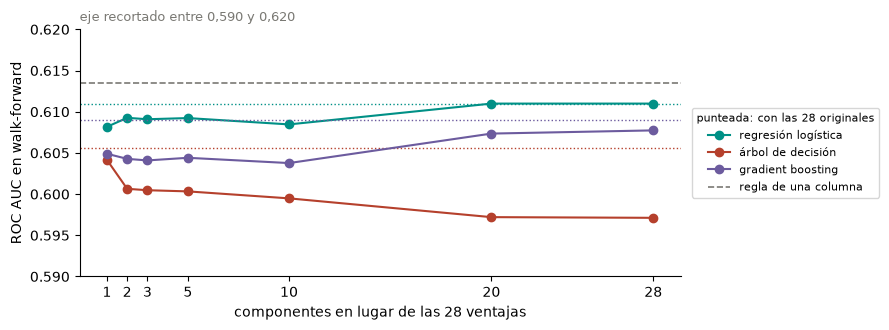

In [43]:
# La curva: AUC en walk-forward según cuántas componentes reemplazan a las 28 ventajas
COLORES = {"regresión logística": VERDE_AZUL, "árbol de decisión": TERRACOTA, "gradient boosting": "#6C5B9E"}
regla_auc = comparacion.loc["regla: una columna", "AUC"]
valores = np.r_[curva_pca.to_numpy().ravel(), sin_pca["AUC"].astype(float), regla_auc]
abajo, arriba = np.floor(valores.min() * 200 - 1) / 200, np.ceil(valores.max() * 200 + 1) / 200

fig, ax = plt.subplots(figsize=(9, 3.4))
for nombre in curva_pca:
    ax.plot(curva_pca.index, curva_pca[nombre], marker="o", color=COLORES[nombre], label=nombre)
    ax.axhline(sin_pca.loc[nombre, "AUC"], color=COLORES[nombre], ls=":", lw=1)
ax.axhline(regla_auc, color=GRIS, ls="--", lw=1.2, label="regla de una columna")
ax.set_xlabel("componentes en lugar de las 28 ventajas"); ax.set_ylabel("ROC AUC en walk-forward")
ax.set_ylim(abajo, arriba); ax.set_xticks(COMPONENTES)
ax.set_title(f"eje recortado entre {c(abajo)} y {c(arriba)}", fontsize=9, color=GRIS, loc="left")
ax.legend(fontsize=8, title="punteada: con las 28 originales", title_fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()
plt.show()

In [44]:
log_pca = curva_pca["regresión logística"]
desvio_pca = sin_pca.loc["regresión logística", "desvío AUC"]
recorrido = log_pca.max() - log_pca.min()
arbol_1, arbol_28 = curva_pca.loc[1, "árbol de decisión"], sin_pca.loc["árbol de decisión", "AUC"]
pca_supera_regla = curva_pca.max().max() > regla_auc + comparacion.loc["regla: una columna", "desvío AUC"]
leer(f'''La primera componente explica el {varianza[0]:.0%} de la varianza de las 28 ventajas y correlaciona {c(corr_pc1, 2)} con `hero_winrate_adv_mean`{': es casi la misma columna que usa la regla' if corr_pc1 > 0.9 else ''}. Con esa sola componente la logística da AUC {c(log_pca.loc[1])}, y con las {COMPONENTES[-1]} componentes {c(log_pca.iloc[-1])}, lo mismo que con las 28 originales ({c(sin_pca.loc['regresión logística', 'AUC'])}): girar los ejes no cambia un modelo lineal. Entre una componente y todas, la curva de la logística se mueve {c(recorrido, 4)} de AUC, {'menos que el desvío (' + c(desvio_pca, 4) + '): agregar direcciones no agrega información' if recorrido < desvio_pca else 'más que el desvío (' + c(desvio_pca, 4) + '): las direcciones de menos varianza también dicen algo'}.

El árbol con una componente da {c(arbol_1)}, {'más' if arbol_1 > arbol_28 else 'menos'} que con las 28 originales ({c(arbol_28)}){': la componente es un corte oblicuo —un poco de cada ventaja— servido en una sola columna, y el árbol, que corta de a una columna por vez, lo aprovecha' if arbol_1 > arbol_28 else ''}.

{'Ninguna curva supera a la regla de una columna (' + c(regla_auc) + ') por más que su desvío. Es la lectura de toda la sección 6: la información de las 28 ventajas está casi toda en una sola dirección, y la regla es esa dirección elegida por lo que se quiere predecir y no por la varianza. PCA no entra al modelo final, y la composición no lo necesita: la columna de la regla es una combinación de las 38 columnas de composición (sección 5§2), así que esa dirección la puede aprender sola de las partidas.' if not pca_supera_regla else 'La mejor curva supera a la regla de una columna (' + c(regla_auc) + ') por más que su desvío.'}''')

La primera componente explica el 26% de la varianza de las 28 ventajas y correlaciona 0,95 con `hero_winrate_adv_mean`: es casi la misma columna que usa la regla. Con esa sola componente la logística da AUC 0,608, y con las 28 componentes 0,611, lo mismo que con las 28 originales (0,611): girar los ejes no cambia un modelo lineal. Entre una componente y todas, la curva de la logística se mueve 0,0028 de AUC, menos que el desvío (0,0049): agregar direcciones no agrega información.

El árbol con una componente da 0,604, menos que con las 28 originales (0,606).

Ninguna curva supera a la regla de una columna (0,613) por más que su desvío. Es la lectura de toda la sección 6: la información de las 28 ventajas está casi toda en una sola dirección, y la regla es esa dirección elegida por lo que se quiere predecir y no por la varianza. PCA no entra al modelo final, y la composición no lo necesita: la columna de la regla es una combinación de las 38 columnas de composición (sección 5.2), así que esa dirección la puede aprender sola de las partidas.

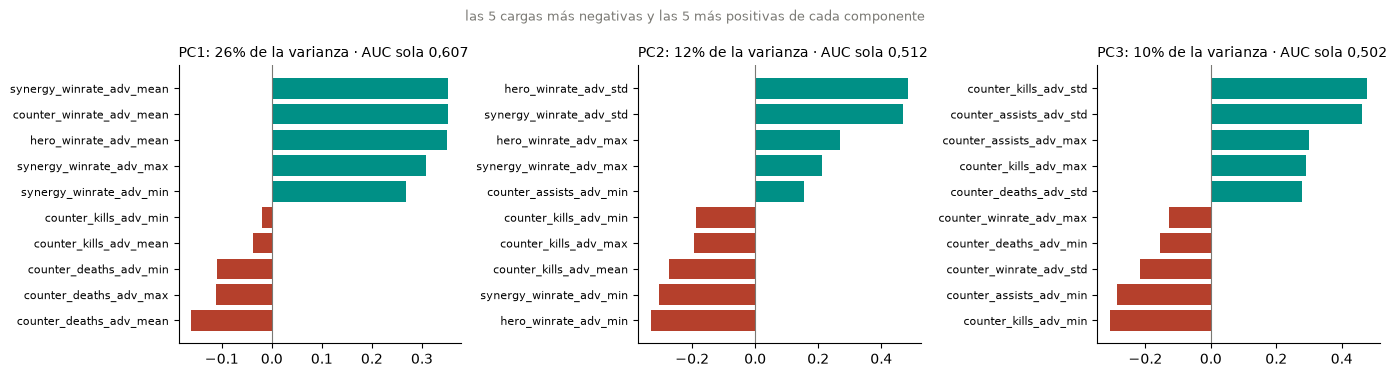

In [45]:
# Qué son esas direcciones: las cargas de las tres primeras componentes (el PCA descriptivo de la tabla de arriba)
from sklearn.metrics import roc_auc_score

pca_desc = descripcion.named_steps["pca"]
puntajes = descripcion.transform(X_train[columnas_ventajas])
auc_sola = [max(a, 1 - a) for a in (roc_auc_score(y_train, puntajes[:, k]) for k in range(3))]   # el signo de una componente es arbitrario
cargas_pc = lambda k: pd.Series(pca_desc.components_[k], index=columnas_ventajas)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for k, ax in enumerate(axes):
    cargas = cargas_pc(k).sort_values()
    extremos = pd.concat([cargas.head(5), cargas.tail(5)])
    ax.barh(extremos.index, extremos.values, color=np.where(extremos.values > 0, VERDE_AZUL, TERRACOTA))
    ax.axvline(0, color=GRIS, lw=0.8)
    ax.set_title(f"PC{k + 1}: {pca_desc.explained_variance_ratio_[k]:.0%} de la varianza · AUC sola {c(auc_sola[k])}", fontsize=10, loc="left")
    ax.tick_params(axis="y", labelsize=8)
fig.suptitle("las 5 cargas más negativas y las 5 más positivas de cada componente", fontsize=9, color=GRIS)
plt.tight_layout()
plt.show()

In [46]:
MEDIAS = ["hero_winrate_adv_mean", "counter_winrate_adv_mean", "synergy_winrate_adv_mean"]
mismo_signo = len({np.sign(cargas_pc(0)[k]) for k in MEDIAS}) == 1
pesan = lambda k, n=3: ", ".join(f"`{x}`" for x in cargas_pc(k).abs().sort_values(ascending=False).index[:n])
leer(f'''**Qué son esas direcciones.** En PC1 las columnas que más pesan son {pesan(0)}{'; las tres medias de winrate (individual, cruces y parejas) pesan con el mismo signo, así que PC1 es la **fuerza general** de A frente a B' if mismo_signo else ''}. Sola, separa las partidas con AUC {c(auc_sola[0])}. PC2 la arman sobre todo {pesan(1)}, y PC3 {pesan(2)}: {'describen cómo está armado cada equipo —qué tan parejos son sus héroes, cómo se reparten las peleas— y no cuál es mejor, y solas dan AUC ' + c(auc_sola[1]) + ' y ' + c(auc_sola[2]) + ', casi el piso' if max(auc_sola[1:]) < 0.52 else 'solas dan AUC ' + c(auc_sola[1]) + ' y ' + c(auc_sola[2])}. Es la curva de arriba vista por dentro: la varianza que se agrega después de PC1 es real, pero no dice quién gana.

*El AUC de cada componente sola se calcula con todas las partidas de entrenamiento juntas, sin walk-forward: sirve para describir las direcciones, no para elegir un modelo.*''')

**Qué son esas direcciones.** En PC1 las columnas que más pesan son `synergy_winrate_adv_mean`, `counter_winrate_adv_mean`, `hero_winrate_adv_mean`; las tres medias de winrate (individual, cruces y parejas) pesan con el mismo signo, así que PC1 es la **fuerza general** de A frente a B. Sola, separa las partidas con AUC 0,607. PC2 la arman sobre todo `hero_winrate_adv_std`, `synergy_winrate_adv_std`, `hero_winrate_adv_min`, y PC3 `counter_kills_adv_std`, `counter_assists_adv_std`, `counter_kills_adv_min`: describen cómo está armado cada equipo —qué tan parejos son sus héroes, cómo se reparten las peleas— y no cuál es mejor, y solas dan AUC 0,512 y 0,502, casi el piso. Es la curva de arriba vista por dentro: la varianza que se agrega después de PC1 es real, pero no dice quién gana.

*El AUC de cada componente sola se calcula con todas las partidas de entrenamiento juntas, sin walk-forward: sirve para describir las direcciones, no para elegir un modelo.*

## 7. El modelo final, leído

Todo lo anterior se eligió con el walk-forward sobre el entrenamiento. Recién ahora se da el paso final de la ventana deslizante: el modelo elegido se entrena **con los últimos `m` cortes de entrenamiento** y se mira el test, **una vez**. Al lado van tres referencias entrenadas igual, que no son candidatas: el piso, la regla de una columna y el modelo que se eligió en la Entrega 3.

**Sobre el test.** El corte de test ya se miró en la Entrega 3, con el modelo de `winrates (3)`. La composición se mide acá por primera vez, y nada de lo que se eligió en las secciones 5 y 6 miró el test: el empate y el criterio de la sección 5.2, el ajuste de la 5.4 y la ventana de la 5.5 salen del walk-forward sobre el entrenamiento.

In [47]:
from sklearn.metrics import roc_auc_score, accuracy_score

ultimos = sorted(g_train.unique())[-VENTANA_FINAL:]   # el paso final de la ventana deslizante
X_final, y_final = X_train[g_train.isin(ultimos)], y_train[g_train.isin(ultimos)]
modelo_final.fit(X_final, y_final)
p_test = modelo_final.predict_proba(X_test)[:, 1]
pred_test = (p_test >= 0.5).astype(int)

E3 = f"referencia: Entrega 3, {legible(elegida_e3['param_elegir__bloques'])}"
ELEGIDO = f"elegido: {NOMBRE_FINAL}"
referencias = {"piso (dummy)": (clone(modelos["piso (dummy)"]), comparacion.loc["piso (dummy)", "AUC"]),
               "regla: una columna": (clone(modelos["regla: una columna"]), comparacion.loc["regla: una columna", "AUC"]),
               E3: (clone(lr.estimator).set_params(**elegida_e3["params"]), elegida_e3["mean_test_auc"])}
filas = {}
for nombre, (m_, auc_val) in referencias.items():
    m_.fit(X_final, y_final)
    filas[nombre] = {"AUC en validación": auc_val, "AUC en test": roc_auc_score(y_test, m_.predict_proba(X_test)[:, 1]),
                     "accuracy en test": accuracy_score(y_test, m_.predict(X_test))}
filas[ELEGIDO] = {"AUC en validación": auc_cv_final, "AUC en test": roc_auc_score(y_test, p_test), "accuracy en test": accuracy_score(y_test, pred_test)}
resultado = pd.DataFrame(filas).T
resultado["caída validación → test"] = resultado["AUC en validación"] - resultado["AUC en test"]
resultado.round(4)

,AUC en validación,AUC en test,accuracy en test,caída validación → test
piso (dummy),0.5000,0.5000,0.5021,0.0000
regla: una columna,0.6135,0.6075,0.5744,0.0060
"referencia: Entrega 3, winrates (3)",0.6140,0.6089,0.5766,0.0052
elegido: regresión logística sobre la composición,0.6139,0.6046,0.5733,0.0093


In [48]:
auc_t, acc_t = roc_auc_score(y_test, p_test), accuracy_score(y_test, pred_test)
acc_piso = resultado.loc["piso (dummy)", "accuracy en test"]
caida = resultado["caída validación → test"]
dif_e3 = auc_t - resultado.loc[E3, "AUC en test"]
leer(f'''Entrenado con `{', '.join(ultimos)}` ({miles(len(X_final))} partidas). En el corte `{CORTE_TEST}`, que el modelo no vio, el AUC es **{c(auc_t)}** y la accuracy **{c(acc_t)}**: acierta {acc_t:.1%} de las partidas contra {acc_piso:.1%} del piso, **{(acc_t - acc_piso) * 100:.1f} puntos más**.

En validación había dado {c(auc_cv_final)} ± {c(desvio_cv_final)}, y en el test cae {c(caida[ELEGIDO])}. El corte de test es más difícil para todos: la regla de una columna cae {c(caida['regla: una columna'])} y el modelo de la Entrega 3, {c(caida[E3])}. {f"Frente a ese modelo, la composición queda {c(-dif_e3)} de AUC por debajo en el test. Es el precio de aprender los pesos de las partidas de un corte en lugar de traerlos calculados con 14 días de estadísticas, y la sección 5§5 sugiere por dónde recuperarlo: con más cortes el AUC de validación sube algo. No cambia la elección: el test se mira una vez, y la elección ya estaba hecha." if dif_e3 < 0 else f"Frente a ese modelo, la composición queda {c(dif_e3)} de AUC por encima en el test, sin haber visto las estadísticas de los héroes."}

**¿Es mucho o poco?** Para predecir el resultado de una partida concreta, poco: cuatro de cada diez se erran. Para la pregunta del proyecto —*¿se puede saber quién gana sabiendo sólo la composición?*— es la respuesta: **en parte, y no mucho más que esto**. La composición mueve la balanza unos puntos; el resto lo deciden las doce personas que juegan, y el matchmaking ya iguala sus rangos (H4). Un modelo de composición que diera 70 % sería sospechoso de fuga antes que motivo de festejo.''')

Entrenado con `2026-09-10` (10.000 partidas). En el corte `2026-09-20`, que el modelo no vio, el AUC es **0,605** y la accuracy **0,573**: acierta 57,3% de las partidas contra 50,2% del piso, **7,1 puntos más**.

En validación había dado 0,614 ± 0,002, y en el test cae 0,009. El corte de test es más difícil para todos: la regla de una columna cae 0,006 y el modelo de la Entrega 3, 0,005. Frente a ese modelo, la composición queda 0,004 de AUC por debajo en el test. Es el precio de aprender los pesos de las partidas de un corte en lugar de traerlos calculados con 14 días de estadísticas, y la sección 5.5 sugiere por dónde recuperarlo: con más cortes el AUC de validación sube algo. No cambia la elección: el test se mira una vez, y la elección ya estaba hecha.

**¿Es mucho o poco?** Para predecir el resultado de una partida concreta, poco: cuatro de cada diez se erran. Para la pregunta del proyecto —*¿se puede saber quién gana sabiendo sólo la composición?*— es la respuesta: **en parte, y no mucho más que esto**. La composición mueve la balanza unos puntos; el resto lo deciden las doce personas que juegan, y el matchmaking ya iguala sus rangos (H4). Un modelo de composición que diera 70 % sería sospechoso de fuga antes que motivo de festejo.

### 7.1 Dónde se equivoca

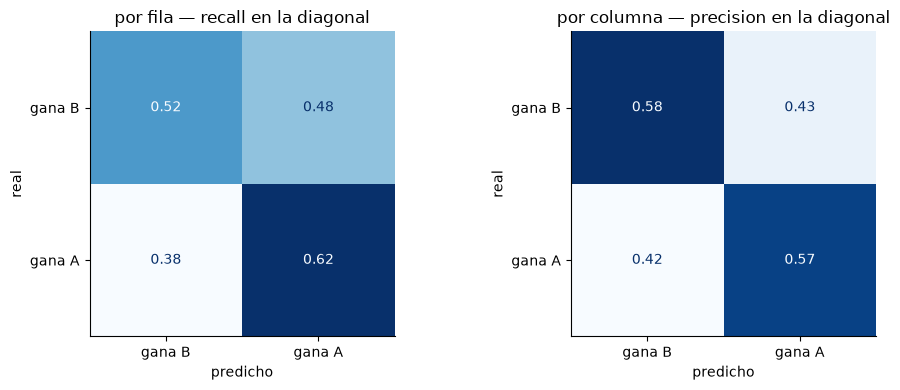

,precision,recall,f1-score,support
gana B,0.579,0.523,0.550,4979.000
gana A,0.568,0.623,0.595,5021.000
accuracy,0.573,0.573,0.573,0.573
macro avg,0.574,0.573,0.572,10000.000
weighted avg,0.574,0.573,0.572,10000.000


In [49]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

nombres = ["gana B", "gana A"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, normalizar, titulo in [(axes[0], "true", "por fila — recall en la diagonal"), (axes[1], "pred", "por columna — precision en la diagonal")]:
    ConfusionMatrixDisplay.from_predictions(y_test, pred_test, ax=ax, cmap="Blues", colorbar=False, normalize=normalizar,
                                            values_format=".2f", display_labels=nombres)
    ax.set_title(titulo); ax.set_xlabel("predicho"); ax.set_ylabel("real")
plt.tight_layout()
plt.show()
pd.DataFrame(classification_report(y_test, pred_test, target_names=nombres, output_dict=True)).T.round(3)

In [50]:
intercepto = modelo_final["modelo"].intercept_[0]
recall = classification_report(y_test, pred_test, target_names=nombres, output_dict=True)
leer(f'''Las dos matrices no son simétricas: el modelo contesta «gana A» en el {pred_test.mean():.1%} de las partidas del test, y A ganó el {y_test.mean():.1%} (recall {c(recall['gana A']['recall'])} para A y {c(recall['gana B']['recall'])} para B). La causa está en el intercepto: con los pesos sumando cero, el intercepto ({c(intercepto)}) es lo que el modelo le da a A cuando los dos equipos son parejos, {1 / (1 + np.exp(-intercepto)):.1%}, y lo aprendió del corte de entrenamiento, en el que A ganó el {y_final.mean():.1%} de las veces. Eso no afecta al AUC, que sólo mira el orden de las probabilidades, y afecta poco a la accuracy, porque las partidas que cambian de lado son las menos seguras (tabla por confianza, más abajo). La confusión no está en una clase sino en **qué tan clara era la partida**, y eso se lee mejor por tramo de confianza y por nivel de juego.''')

Las dos matrices no son simétricas: el modelo contesta «gana A» en el 55,0% de las partidas del test, y A ganó el 50,2% (recall 0,623 para A y 0,523 para B). La causa está en el intercepto: con los pesos sumando cero, el intercepto (0,057) es lo que el modelo le da a A cuando los dos equipos son parejos, 51,4%, y lo aprendió del corte de entrenamiento, en el que A ganó el 51,5% de las veces. Eso no afecta al AUC, que sólo mira el orden de las probabilidades, y afecta poco a la accuracy, porque las partidas que cambian de lado son las menos seguras (tabla por confianza, más abajo). La confusión no está en una clase sino en **qué tan clara era la partida**, y eso se lee mejor por tramo de confianza y por nivel de juego.

In [51]:
analisis = df.loc[es_test, ["match_id", "average_badge", "hero_winrate_adv_mean"]].assign(
    real=y_test.values, prob=p_test, pred=pred_test)
analisis["acierto"] = analisis["real"].eq(analisis["pred"])
analisis["confianza"] = (analisis["prob"] - 0.5).abs()

def por_grupo(columna):
    filas = {}
    for grupo, t in analisis.groupby(columna, observed=True):
        filas[grupo] = {"partidas": len(t), "accuracy": t["acierto"].mean(), "AUC": roc_auc_score(t["real"], t["prob"])}
    return pd.DataFrame(filas).T

analisis["tramo de confianza"] = pd.qcut(analisis["confianza"], 5, labels=["20 % menos seguras", "2.º quintil", "3.º quintil", "4.º quintil", "20 % más seguras"])
analisis["tramo de badge"] = pd.cut(analisis["average_badge"], [0, 40, 60, 80, 200], labels=["≤40", "41-60", "61-80", ">80"])
pd.concat({"por confianza": por_grupo("tramo de confianza"), "por nivel de juego": por_grupo("tramo de badge")}).round(3)

partidas  accuracy    AUC
por confianza      20 % menos seguras    2000.0     0.504  0.507
                   2.º quintil           2000.0     0.548  0.564
                   3.º quintil           2000.0     0.562  0.568
                   4.º quintil           2000.0     0.584  0.583
                   20 % más seguras      2000.0     0.668  0.679
por nivel de juego ≤40                   3376.0     0.577  0.605
                   41-60                 2100.0     0.581  0.611
                   61-80                 1976.0     0.579  0.609
                   >80                   2548.0     0.558  0.596

In [52]:
bajo_medio = df.loc[X_final.index, "average_badge"].le(60).mean()   # qué parte de las partidas de entrenamiento es de nivel 60 o menos
conf = por_grupo("tramo de confianza"); badge = por_grupo("tramo de badge")
leer(f'''**Por confianza.** En el 20 % de partidas donde el modelo está más seguro acierta el **{conf['accuracy'].iloc[-1]:.1%}**; en el 20 % donde está menos seguro, el {conf['accuracy'].iloc[0]:.1%}, prácticamente una moneda. El modelo sabe cuándo no sabe: la mayoría de las partidas tienen composiciones parejas, y ahí la composición no decide.

**Por nivel de juego.** La accuracy va de {badge['accuracy'].min():.1%} (`{badge['accuracy'].idxmin()}`) a {badge['accuracy'].max():.1%} (`{badge['accuracy'].idxmax()}`). La Entrega 2 encontró en H1 que la ventaja de composición separaba menos en el tramo más alto (`>80`); acá ese tramo da {badge.loc['>80', 'accuracy']:.1%}. Una hipótesis de dominio, no medida acá: los pesos se aprenden con todas las partidas del corte de entrenamiento, y el {bajo_medio:.0%} son de nivel 60 o menos; los jugadores de más nivel pueden sacarle rendimiento a héroes que en esas partidas aparecen como flojos.''')

**Por confianza.** En el 20 % de partidas donde el modelo está más seguro acierta el **66,8%**; en el 20 % donde está menos seguro, el 50,4%, prácticamente una moneda. El modelo sabe cuándo no sabe: la mayoría de las partidas tienen composiciones parejas, y ahí la composición no decide.

**Por nivel de juego.** La accuracy va de 55,8% (`>80`) a 58,1% (`41-60`). La Entrega 2 encontró en H1 que la ventaja de composición separaba menos en el tramo más alto (`>80`); acá ese tramo da 55,8%. Una hipótesis de dominio, no medida acá: los pesos se aprenden con todas las partidas del corte de entrenamiento, y el 54% son de nivel 60 o menos; los jugadores de más nivel pueden sacarle rendimiento a héroes que en esas partidas aparecen como flojos.

In [53]:
# Una confusión concreta: las partidas donde el modelo estaba más seguro y se equivocó
heroes_de = lambda fila, signo: ", ".join(k.replace("hero_", "") for k in schema.COMPOSICION if fila[k] == signo)
peores = analisis[~analisis["acierto"]].nlargest(5, "confianza")
detalle = df.loc[peores.index]
pd.DataFrame({"prob. gana A": peores["prob"].round(3), "ganó": np.where(peores["real"] == 1, "A", "B"),
              "ventaja de fuerza": peores["hero_winrate_adv_mean"].round(3), "badge": peores["average_badge"],
              "héroes de A": detalle.apply(heroes_de, axis=1, signo=1), "héroes de B": detalle.apply(heroes_de, axis=1, signo=-1)})

,prob. gana A,ganó,ventaja de fuerza,badge,héroes de A,héroes de B
44044,0.804,B,0.099,46,"wraith, calico, drifter, victor, paige, apollo","lady_geist, holliday, lash, pocket, mirage, mina"
40232,0.803,B,0.095,15,"seven, lady_geist, viscous, victor, paige, celeste","bebop, yamato, pocket, venator, billy, rem"
45032,0.205,A,-0.096,106,"abrams, dynamo, holliday, yamato, mirage, mina","haze, mo_and_krill, lash, victor, paige, graves"
44241,0.208,A,-0.108,75,"infernus, bebop, grey_talon, shiv, pocket, venator","seven, wraith, calico, mo_and_krill, yamato, paige"
43743,0.788,B,0.092,36,"dynamo, calico, drifter, victor, billy, graves","mcginnis, haze, shiv, mina, venator, rem"


In [54]:
coinciden = int((np.sign(peores["hero_winrate_adv_mean"]) == np.sign(peores["prob"] - 0.5)).sum())
leer(f'''En {coinciden} de estos {len(peores)} errores, la ventaja de fuerza que calcula la API —que el modelo no vio— apunta para el mismo lado que el modelo: no es que haya leído mal la composición, es que la composición decía eso y ganó el otro equipo. Es lo esperable en un juego donde la composición es una ventaja de punto de partida y no una sentencia: un equipo con héroes que estadísticamente ganan menos puede ganar igual si los juega mejor. No hay una columna que el modelo esté leyendo mal; hay una variable —quién juega— que no tiene.''')

En 5 de estos 5 errores, la ventaja de fuerza que calcula la API —que el modelo no vio— apunta para el mismo lado que el modelo: no es que haya leído mal la composición, es que la composición decía eso y ganó el otro equipo. Es lo esperable en un juego donde la composición es una ventaja de punto de partida y no una sentencia: un equipo con héroes que estadísticamente ganan menos puede ganar igual si los juega mejor. No hay una columna que el modelo esté leyendo mal; hay una variable —quién juega— que no tiene.

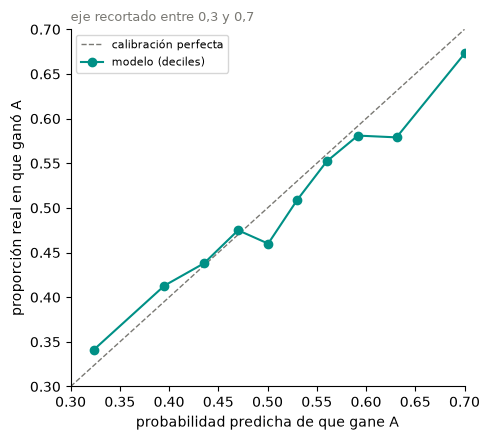

Las probabilidades del modelo van de 17% a 84%: nunca dice "seguro". Por deciles, la diferencia media entre lo que predice y lo que pasa es de 2,0 puntos, así que un "60 %" en la aplicación se puede leer como 60 %.

In [55]:
# La calibración: cuando dice 60 %, ¿gana A el 60 % de las veces? Es lo que va a mostrar la aplicación
from sklearn.calibration import calibration_curve

frac, media = calibration_curve(y_test, p_test, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.plot([0.3, 0.7], [0.3, 0.7], ls="--", color=GRIS, lw=1, label="calibración perfecta")
ax.plot(media, frac, marker="o", color=VERDE_AZUL, label="modelo (deciles)")
ax.set_xlabel("probabilidad predicha de que gane A"); ax.set_ylabel("proporción real en que ganó A")
ax.set_title("eje recortado entre 0,3 y 0,7", fontsize=9, color=GRIS, loc="left"); ax.legend(fontsize=8)
ax.set_xlim(0.3, 0.7); ax.set_ylim(0.3, 0.7)
plt.tight_layout()
plt.show()
leer(f'''Las probabilidades del modelo van de {p_test.min():.0%} a {p_test.max():.0%}: nunca dice "seguro". Por deciles, la diferencia media entre lo que predice y lo que pasa es de {np.abs(frac - media).mean() * 100:.1f} puntos, así que un "60 %" en la aplicación se puede leer como 60 %.''')

### 7.2 En qué se apoya

En una logística sin escalar, el peso de cada héroe se lee directo: es cuánto suben (o bajan) los log-odds de que gane A cuando ese héroe juega en A en lugar de no estar; si juega en B, el mismo peso con el signo cambiado. Como en cada partida hay seis +1 y seis −1, sumarle una constante a todos los pesos no cambia ninguna predicción, y la multa l2 elige la solución en la que suman cero: **cada peso se lee contra el héroe promedio**.

No se usa la importancia por permutación: desordenar una sola columna de héroe arma partidas imposibles, con equipos de cinco o de siete.

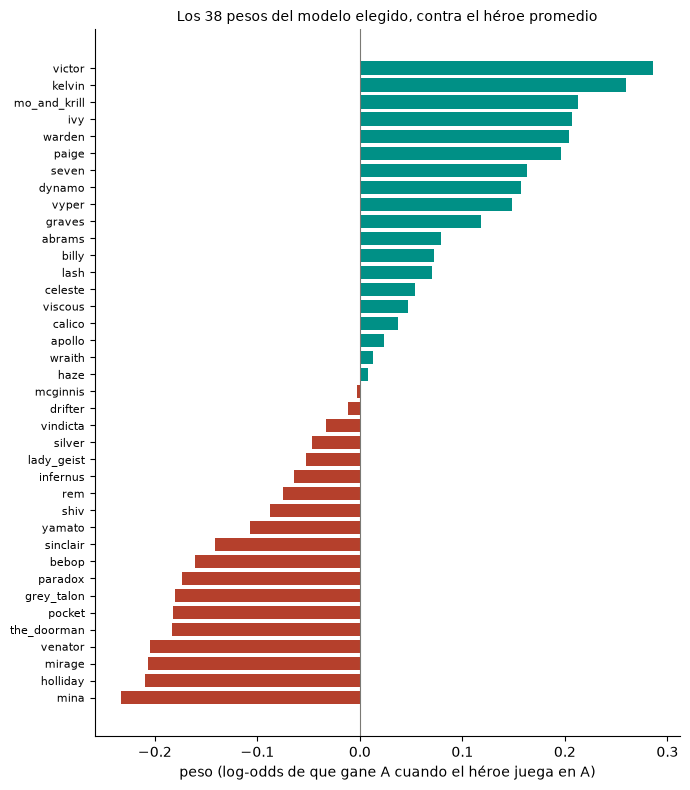

suma de los 38 pesos                    -0.0000
intercepto                               0.0571
probabilidad de A con equipos parejos    0.5143
dtype: float64

In [56]:
lineal = modelo_final["modelo"]
nombre_h = lambda k: k.replace("hero_", "")
pesos_h = pd.Series(lineal.coef_[0], index=[nombre_h(k) for k in modelo_final["elegir"].columnas_])
orden_p = pesos_h.sort_values()
fig, ax = plt.subplots(figsize=(7, 8))
ax.barh(orden_p.index, orden_p.values, color=np.where(orden_p.values > 0, VERDE_AZUL, TERRACOTA))
ax.axvline(0, color=GRIS, lw=0.8)
ax.tick_params(axis="y", labelsize=8)
ax.set_xlabel("peso (log-odds de que gane A cuando el héroe juega en A)")
ax.set_title("Los 38 pesos del modelo elegido, contra el héroe promedio", fontsize=10)
plt.tight_layout()
plt.show()
pd.Series({"suma de los 38 pesos": pesos_h.sum(), "intercepto": lineal.intercept_[0],
           "probabilidad de A con equipos parejos": 1 / (1 + np.exp(-lineal.intercept_[0]))}).round(4)

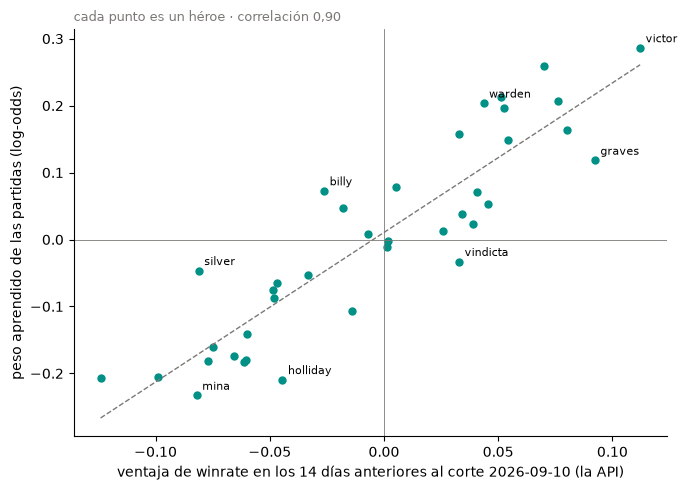

In [57]:
# Los pesos aprendidos de las partidas contra la ventaja de winrate que la API calculó con los 14 días anteriores
externos = winrates_del_corte(ultimos[-1]).rename(index=nombre_h)[pesos_h.index]
r_pesos = np.corrcoef(externos, pesos_h)[0, 1]
pendiente, ordenada = np.polyfit(externos, pesos_h, 1)
residuo = pesos_h - (pendiente * externos + ordenada)
marcar = set(residuo.nlargest(3).index) | set(residuo.nsmallest(3).index) | {pesos_h.idxmax(), pesos_h.idxmin()}

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(externos, pesos_h, color=VERDE_AZUL, s=25)
xs = np.linspace(externos.min(), externos.max(), 2)
ax.plot(xs, pendiente * xs + ordenada, color=GRIS, ls="--", lw=1)
for h in marcar:
    ax.annotate(h, (externos[h], pesos_h[h]), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.axhline(0, color=GRIS, lw=0.6); ax.axvline(0, color=GRIS, lw=0.6)
ax.set_xlabel(f"ventaja de winrate en los 14 días anteriores al corte {ultimos[-1]} (la API)")
ax.set_ylabel("peso aprendido de las partidas (log-odds)")
ax.set_title(f"cada punto es un héroe · correlación {r_pesos:.2f}".replace(".", ","), fontsize=9, color=GRIS, loc="left")
plt.tight_layout()
plt.show()

In [58]:
sig = lambda z: 1 / (1 + np.exp(-z))
b0, top_pos, top_neg = lineal.intercept_[0], pesos_h.idxmax(), pesos_h.idxmin()
leer(f'''**Los héroes que más pesan.** El que más empuja a favor de su equipo es `{top_pos}` ({c(pesos_h[top_pos])}): con dos equipos parejos, ponerlo en A en lugar de un héroe promedio lleva la probabilidad de A de {sig(b0):.1%} a {sig(b0 + pesos_h[top_pos]):.1%}. El que más empuja en contra es `{top_neg}` ({c(pesos_h[top_neg])}), que la baja a {sig(b0 + pesos_h[top_neg]):.1%}. Ningún héroe decide una partida por sí solo: la composición pesa por acumulación.

**Lo aprendió de las partidas, y coincide con la API.** Los 38 pesos correlacionan **{c(r_pesos, 2)}** con la ventaja de winrate que la API calculó con los 14 días anteriores al corte, un dato que el modelo nunca vio. Los que más se apartan de la recta son {', '.join(f'`{h}`' for h in residuo.nlargest(2).index)} (el modelo los ve más fuertes que la API) y {', '.join(f'`{h}`' for h in residuo.nsmallest(2).index)} (más débiles). Una explicación posible, no verificada: la API resume los 14 días anteriores, y el modelo, las partidas del día del corte; un héroe que se empezó a jugar distinto de una ventana a la otra se separa de la recta.

**Por qué no es una fuga.** (1) La composición se conoce al terminar la selección de héroes, antes de que empiece la partida: no puede contener el resultado. (2) Si lo contuviera, el AUC estaría cerca de 1, no en {c(auc_t)}. (3) Partir al azar cambia el número apenas {c(azar_comp['AUC'] - auc_cv_final)} (sección 5§6): el modelo no depende de ver el mismo momento del juego de los dos lados. (4) Lo que aprendió se parece a estadísticas de días anteriores a estas partidas (r = {c(r_pesos, 2)}): es fuerza de héroes, no algo propio de estas partidas.''')

**Los héroes que más pesan.** El que más empuja a favor de su equipo es `victor` (0,286): con dos equipos parejos, ponerlo en A en lugar de un héroe promedio lleva la probabilidad de A de 51,4% a 58,5%. El que más empuja en contra es `mina` (-0,233), que la baja a 45,6%. Ningún héroe decide una partida por sí solo: la composición pesa por acumulación.

**Lo aprendió de las partidas, y coincide con la API.** Los 38 pesos correlacionan **0,90** con la ventaja de winrate que la API calculó con los 14 días anteriores al corte, un dato que el modelo nunca vio. Los que más se apartan de la recta son `silver`, `billy` (el modelo los ve más fuertes que la API) y `holliday`, `vindicta` (más débiles). Una explicación posible, no verificada: la API resume los 14 días anteriores, y el modelo, las partidas del día del corte; un héroe que se empezó a jugar distinto de una ventana a la otra se separa de la recta.

**Por qué no es una fuga.** (1) La composición se conoce al terminar la selección de héroes, antes de que empiece la partida: no puede contener el resultado. (2) Si lo contuviera, el AUC estaría cerca de 1, no en 0,605. (3) Partir al azar cambia el número apenas 0,002 (sección 5.6): el modelo no depende de ver el mismo momento del juego de los dos lados. (4) Lo que aprendió se parece a estadísticas de días anteriores a estas partidas (r = 0,90): es fuerza de héroes, no algo propio de estas partidas.

## 8. El modelo que se lleva la Entrega 4

Se guarda sin el paso `ElegirColumnas`, que es una clase de este notebook: así la aplicación no necesita definirla para cargar el modelo. Lo que recibe es una fila con las 38 columnas de composición, en el orden de `schema.COMPOSICION`. La función de abajo es lo que va a hacer la aplicación: de los 6 + 6 héroes elegidos a la probabilidad de que gane A, sin bajar ninguna estadística.

In [59]:
import joblib

DESTINO = RAIZ / "notebooks" / "modelo_entrega3_composicion.joblib"
joblib.dump({"modelo": Pipeline(modelo_final.steps[1:]), "columnas": schema.COMPOSICION, "heroes": schema.HEROES,
             "cortes_entrenamiento": ultimos, "corte_test": CORTE_TEST, "semilla": SEMILLA}, DESTINO)
print("guardado:", DESTINO.relative_to(RAIZ))

guardado: notebooks\modelo_entrega3_composicion.joblib


In [60]:
paquete = joblib.load(DESTINO)
CONOCIDOS = {slug for _, slug in paquete["heroes"]}


def probabilidad_gana_A(heroes_a, heroes_b):
    '''De los 6 + 6 héroes elegidos (por su nombre) a la probabilidad de que gane A.'''
    assert len(set(heroes_a)) == 6 and len(set(heroes_b)) == 6 and not set(heroes_a) & set(heroes_b), "6 héroes distintos por equipo"
    desconocidos = (set(heroes_a) | set(heroes_b)) - CONOCIDOS
    if desconocidos:
        print("sin peso propio, cuentan como un héroe promedio:", ", ".join(sorted(desconocidos)))
    fila = [[1 if s in heroes_a else -1 if s in heroes_b else 0 for _, s in paquete["heroes"]]]
    return paquete["modelo"].predict_proba(pd.DataFrame(fila, columns=paquete["columnas"]))[0, 1]


partida = df.loc[es_test].iloc[0]
heroes_a = [nombre_h(k) for k in schema.COMPOSICION if partida[k] == 1]
heroes_b = [nombre_h(k) for k in schema.COMPOSICION if partida[k] == -1]
pd.Series({"héroes de A": ", ".join(heroes_a), "héroes de B": ", ".join(heroes_b),
           "probabilidad de que gane A (cargado del archivo)": round(probabilidad_gana_A(heroes_a, heroes_b), 4),
           "la misma partida en la sección 7": round(p_test[0], 4), "ganó": partida["winner"]})

héroes de A                                         seven, holliday, shiv, lash, mirage, drifter
héroes de B                                          wraith, calico, ivy, yamato, graves, silver
probabilidad de que gane A (cargado del archivo)                                          0.3901
la misma partida en la sección 7                                                          0.3901
ganó                                                                                           A
dtype: object

Un aviso para la aplicación: entre el 21/09 y el 19/10 Valve agregó **cinco héroes nuevos** (ids 78, 84, 85, 86 y 88), y el catálogo del pipeline tiene 38. El modelo de composición no tiene columna para un héroe que no vio: en la función de arriba, un héroe desconocido aporta 0, que —como los pesos suman cero— es lo mismo que tratarlo como un héroe promedio. El modelo de ventajas hacía lo mismo: el DAG le asigna ventaja 0 a un héroe sin estadísticas (`_hero_adv`, en `transform.py`). En los dos casos, para que un héroe nuevo pese hay que agregarlo a `schema.HEROES`; la composición, además, tiene que reentrenarse con un corte en el que aparezca, que con `m = 1` es el corte siguiente.

In [61]:
leer(f'''## Cierre

- **Qué se predice:** si gana el equipo A, con ROC AUC como métrica y accuracy al lado.
- **Contra qué:** el piso es {c(comparacion.loc['piso (dummy)', 'accuracy'])} de accuracy; la regla de una columna, {c(comparacion.loc['regla: una columna', 'accuracy'])} en validación.
- **Cómo se partió:** walk-forward con ventana deslizante de {VENTANA_FINAL} corte, porque el modelo se usa sobre un momento del juego que no vio; el final se entrenó con `{', '.join(ultimos)}` y el test es el corte `{CORTE_TEST}`.
- **Qué se eligió:** {NOMBRE_FINAL}, con los 38 héroes en ±1, sin escalar, multa {elegida_aj['multa']} y `C = {C_final:g}`. Empata con la mejor combinación de la grilla y es la única del empate que no necesita las estadísticas de los héroes; sobre las mismas columnas, ningún árbol, bosque o boosting le gana.
- **Cuánto da:** AUC {c(auc_t)} y accuracy {c(acc_t)} en el test; el modelo de la Entrega 3 da {c(resultado.loc[E3, 'AUC en test'])} en el mismo corte.
- **En qué se apoya:** un peso por héroe, que correlaciona {c(r_pesos, 2)} con el winrate que calcula la API sin haberlo visto.
- **Qué no aportó nada medible:** sumarle las estadísticas de los héroes, aprender los cruces y las parejas, un peso por lado, los modelos de árboles, `average_badge_diff`{', y comprimir las 28 ventajas con PCA' if not pca_supera_regla else ''}.
- **Límites:** el test ya se había mirado en la Entrega 3 con otro modelo; la ventana más larga sube un poco el AUC, pero menos que el desvío, y conviene volver a medirla con más cortes; las fechas medidas tuvieron parches mínimos; y los cinco héroes nuevos quedan como héroes promedio hasta que entren al catálogo.''')

## Cierre

- **Qué se predice:** si gana el equipo A, con ROC AUC como métrica y accuracy al lado.
- **Contra qué:** el piso es 0,501 de accuracy; la regla de una columna, 0,580 en validación.
- **Cómo se partió:** walk-forward con ventana deslizante de 1 corte, porque el modelo se usa sobre un momento del juego que no vio; el final se entrenó con `2026-09-10` y el test es el corte `2026-09-20`.
- **Qué se eligió:** regresión logística sobre la composición, con los 38 héroes en ±1, sin escalar, multa l2 y `C = 0.1`. Empata con la mejor combinación de la grilla y es la única del empate que no necesita las estadísticas de los héroes; sobre las mismas columnas, ningún árbol, bosque o boosting le gana.
- **Cuánto da:** AUC 0,605 y accuracy 0,573 en el test; el modelo de la Entrega 3 da 0,609 en el mismo corte.
- **En qué se apoya:** un peso por héroe, que correlaciona 0,90 con el winrate que calcula la API sin haberlo visto.
- **Qué no aportó nada medible:** sumarle las estadísticas de los héroes, aprender los cruces y las parejas, un peso por lado, los modelos de árboles, `average_badge_diff`, y comprimir las 28 ventajas con PCA.
- **Límites:** el test ya se había mirado en la Entrega 3 con otro modelo; la ventana más larga sube un poco el AUC, pero menos que el desvío, y conviene volver a medirla con más cortes; las fechas medidas tuvieron parches mínimos; y los cinco héroes nuevos quedan como héroes promedio hasta que entren al catálogo.